In [ ]:
Full Version (Revised)
# Steps:
#   1. Data download & descriptive statistics
#   2. Correlation analysis (full sample + stress windows + Fisher z test)
#   3. Portfolio construction & stress-scenario performance
#   4. Static optimization (MV, Mean-CVaR via LP, Min-Var, Risk Parity, Ledoit-Wolf)
#   5. Rolling out-of-sample optimization (with trading costs, multi-window)
#   6. Factor regressions (CAPM / FF3 / FF3 + TERM + DEF, Newey-West HAC)
#   7. Factor-matched control portfolios
#   8. Put the two halves of the thesis on the SAME ruler
#   9. Statistical inference on performance differences
#   10.Factor risk decomposition + HAC-lag robustness + units


# ============================================================


# ============================================================
# STEP 1: Download ETF data, compute daily/monthly returns, descriptive stats
# Assets: LQD (IG), HYG (HY), VNQ (REITs), IGF (Infrastructure), SPY (Equity), TLT (Long Treasury)
# Period: 2010-01-01 to 2025-12-31
# ============================================================

import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

# ---------- 1.1 Download prices ----------
tickers = ["LQD", "HYG", "VNQ", "IGF", "SPY", "TLT"]

data = yf.download(tickers, start="2010-01-01", end="2026-01-01",
                   progress=False, auto_adjust=True)

daily_prices = data["Close"].reindex(columns=tickers).sort_index()
if daily_prices.empty or daily_prices.isna().any().any():
    missing = daily_prices.isna().sum().to_dict()
    raise ValueError(f"Missing ETF prices; verify download and sample: {missing}")
print("Daily price shape:", daily_prices.shape)
print("Time range:", daily_prices.index[0].date(), "->", daily_prices.index[-1].date())

# ---------- 1.1B Risk-free proxy: 13-week US T-bill yield (^IRX) ----------
rf_raw = yf.download("^IRX", start="2010-01-01", end="2026-01-01",
                     progress=False, auto_adjust=True)
rf_annual_yield = rf_raw["Close"].squeeze() / 100.0
if rf_annual_yield.empty:
    raise ValueError("Risk-free proxy ^IRX download returned no observations")

# Key fix: only forward-fill (no bfill -> no look-ahead bias).
rf_annual_yield = rf_annual_yield.reindex(daily_prices.index).ffill()
valid_mask = rf_annual_yield.notna()
daily_prices = daily_prices.loc[valid_mask]
rf_annual_yield = rf_annual_yield.loc[valid_mask]

rf_daily = (1.0 + rf_annual_yield) ** (1.0 / 252.0) - 1.0
rf_monthly = ((1.0 + rf_annual_yield).resample("ME").last() ** (1.0 / 12.0) - 1.0)
rf_monthly.index = rf_monthly.index.to_period("M")

# ---------- 1.2 Daily & monthly returns ----------
daily_returns = daily_prices.pct_change().dropna()

monthly_prices = daily_prices.resample("ME").last()
monthly_returns = monthly_prices.pct_change().dropna()
monthly_returns.index = monthly_returns.index.to_period("M")

print("\nMonthly return shape:", monthly_returns.shape)
print("Time range:", monthly_returns.index[0], "->", monthly_returns.index[-1])

# ---------- 1.3 Descriptive statistics ----------
ann_ret = daily_returns.mean() * 252 * 100
ann_vol = daily_returns.std() * np.sqrt(252) * 100

excess_daily_returns = daily_returns.sub(rf_daily, axis=0).dropna()
sharpe = (excess_daily_returns.mean() * 252) / (
    daily_returns.loc[excess_daily_returns.index].std() * np.sqrt(252))

cum = (1 + daily_returns).cumprod()
dd = cum.div(cum.cummax()) - 1
max_dd = dd.min() * 100

stats = pd.DataFrame({
    "Ann. Return (%)": ann_ret.round(2),
    "Ann. Vol (%)":    ann_vol.round(2),
    "Sharpe":          sharpe.round(3),
    "Max DD (%)":      max_dd.round(2),
})
print("\n=== Descriptive statistics (2010-2025, daily annualised) ===")
print(stats.to_string())

# ---------- 1.4 Save ----------
daily_returns.to_parquet("daily_returns.parquet")
monthly_returns.to_parquet("monthly_returns.parquet")
rf_daily.rename("RF").to_frame().to_parquet("rf_daily.parquet")
rf_monthly.rename("RF").to_frame().to_parquet("rf_monthly.parquet")
print("\nSaved: daily_returns.parquet, monthly_returns.parquet, rf_daily.parquet, rf_monthly.parquet")



Daily price shape: (4024, 6)
Time range: 2010-01-04 -> 2025-12-31

Monthly return shape: (191, 6)
Time range: 2010-02 -> 2025-12

=== Descriptive statistics (2010-2025, daily annualised) ===
        Ann. Return (%)  Ann. Vol (%)  Sharpe  Max DD (%)
Ticker                                                   
LQD                4.26          7.66   0.380      -24.95
HYG                5.53          8.33   0.502      -22.03
VNQ               10.34         20.50   0.439      -42.40
IGF                8.22         17.07   0.403      -42.11
SPY               14.53         17.21   0.766      -33.72
TLT                3.83         15.10   0.164      -48.35

Saved: daily_returns.parquet, monthly_returns.parquet, rf_daily.parquet, rf_monthly.parquet


Daily data: (4023, 6), range: 2010-01-05 -> 2025-12-31

Full-sample correlation matrix (daily, 2010-2025)
Ticker    LQD    HYG    VNQ    IGF    SPY    TLT
Ticker                                          
LQD     1.000  0.419  0.313  0.253  0.191  0.678
HYG     0.419  1.000  0.684  0.746  0.765 -0.106
VNQ     0.313  0.684  1.000  0.771  0.749 -0.096
IGF     0.253  0.746  0.771  1.000  0.813 -0.212
SPY     0.191  0.765  0.749  0.813  1.000 -0.298
TLT     0.678 -0.106 -0.096 -0.212 -0.298  1.000


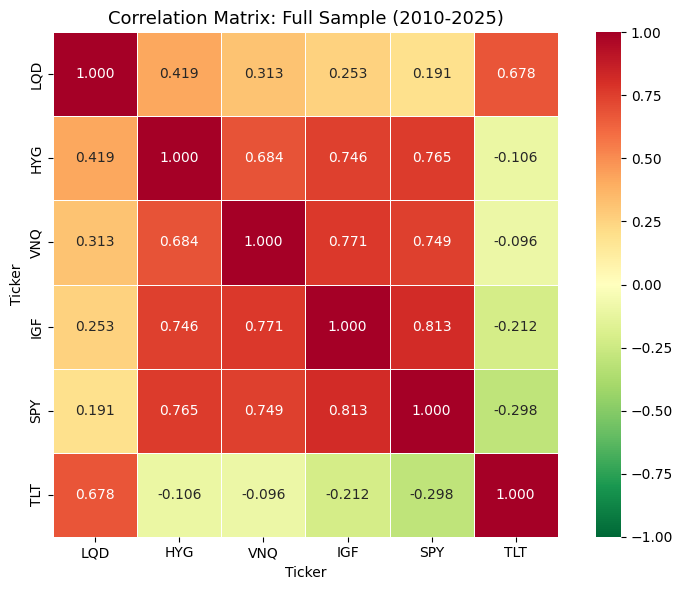


Correlation with SPY: normal vs stress (main windows)
        Normal (2015-2019)  COVID-19 Crash  2022 Rate Hike  Tightening Cycle
Ticker                                                                      
LQD                 -0.040           0.244           0.471             0.422
HYG                  0.714           0.917           0.806             0.790
VNQ                  0.557           0.945           0.820             0.792
IGF                  0.731           0.948           0.820             0.797
TLT                 -0.351          -0.503           0.085             0.064

Correlation change vs normal period
        Normal (2015-2019)  COVID-19 Crash  2022 Rate Hike  Tightening Cycle
Ticker                                                                      
LQD                    0.0           0.284           0.511             0.462
HYG                    0.0           0.203           0.092             0.076
VNQ                    0.0           0.388           0.263   

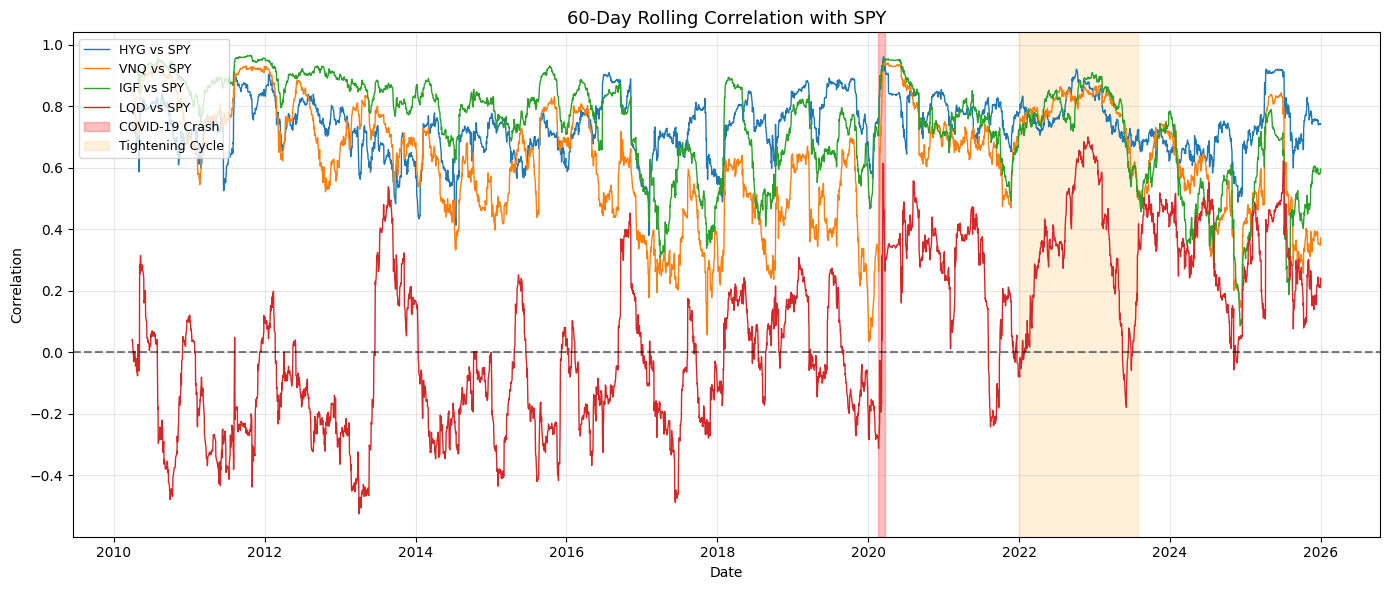

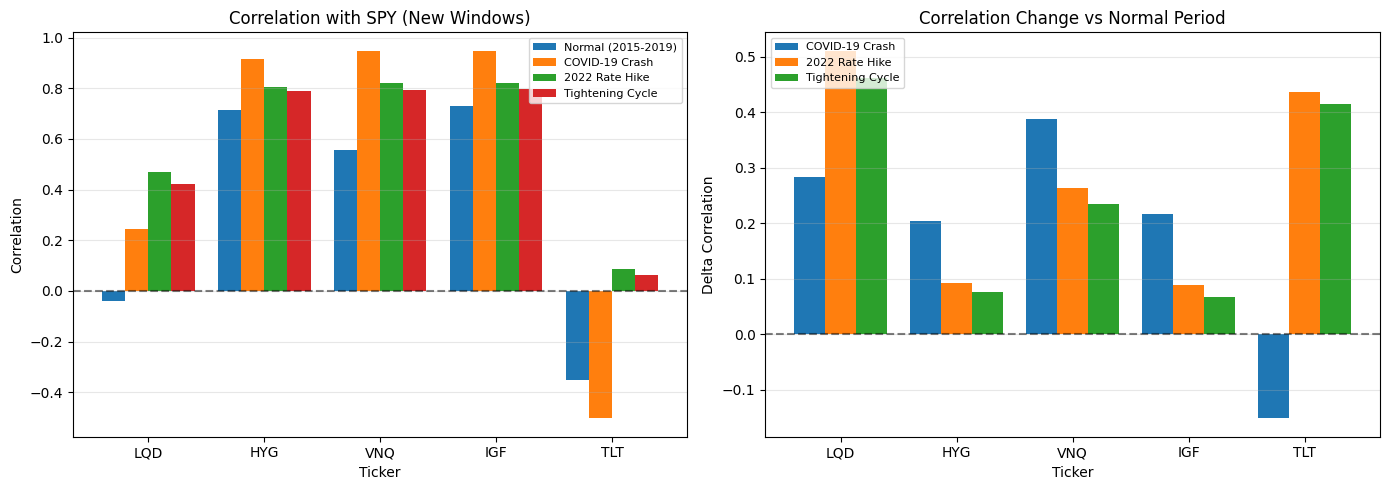


Saved correlation outputs.


In [2]:
# ============================================================
# STEP 2: Correlation analysis
# - Full-sample correlation matrix
# - Normal vs stress windows
# - 60-day rolling correlation
# - Robustness: wide stress windows
# - Fisher z-test: is the correlation shift significant?
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import warnings
warnings.filterwarnings("ignore")

# ---------- 2.1 Load ----------
daily_returns = pd.read_parquet("daily_returns.parquet")
print(f"Daily data: {daily_returns.shape}, range: {daily_returns.index[0].date()} -> {daily_returns.index[-1].date()}")

# ---------- 2.2 Full-sample correlation ----------
corr_full = daily_returns.corr()
print("\n" + "=" * 70)
print("Full-sample correlation matrix (daily, 2010-2025)")
print("=" * 70)
print(corr_full.round(3).to_string())

plt.figure(figsize=(8, 6))
sns.heatmap(corr_full, annot=True, cmap="RdYlGn_r", vmin=-1, vmax=1, fmt=".3f",
            square=True, linewidths=0.5)
plt.title("Correlation Matrix: Full Sample (2010-2025)", fontsize=13)
plt.tight_layout(); plt.savefig("corr_full.png", dpi=150); plt.show()

# ---------- 2.3 Main stress windows ----------
windows_main = {
    "Normal (2015-2019)":  ("2015-01-01", "2019-12-31"),
    "COVID-19 Crash":      ("2020-02-19", "2020-03-23"),
    "2022 Rate Hike":      ("2022-01-01", "2022-12-31"),
    "Tightening Cycle":    ("2022-01-01", "2023-07-31"),
}
results_main = {}
for label, (s, e) in windows_main.items():
    sub = daily_returns.loc[s:e]
    results_main[label] = sub.corr()["SPY"].drop("SPY")

corr_main_df = pd.DataFrame(results_main).round(3)
print("\n" + "=" * 70)
print("Correlation with SPY: normal vs stress (main windows)")
print("=" * 70)
print(corr_main_df.to_string())

delta_main = corr_main_df.sub(corr_main_df["Normal (2015-2019)"], axis=0)
print("\n" + "=" * 70)
print("Correlation change vs normal period")
print("=" * 70)
print(delta_main.round(3).to_string())

# ---------- 2.3B Fisher z-test ----------
def fisher_z_test(r1, r2, n1, n2):
    z1, z2 = np.arctanh(r1), np.arctanh(r2)
    se = np.sqrt(1.0 / (n1 - 3) + 1.0 / (n2 - 3))
    z_stat = (z1 - z2) / se
    p_val = 2 * (1 - stats.norm.cdf(abs(z_stat)))
    return z_stat, p_val

n_normal = len(daily_returns.loc["2015-01-01":"2019-12-31"])
n_covid  = len(daily_returns.loc["2020-02-19":"2020-03-23"])

sig_test = {}
for ticker in ["HYG", "IGF", "LQD", "VNQ"]:
    r_n = corr_main_df.loc[ticker, "Normal (2015-2019)"]
    r_c = corr_main_df.loc[ticker, "COVID-19 Crash"]
    z_stat, p_val = fisher_z_test(r_n, r_c, n_normal, n_covid)
    sig_test[ticker] = {
        "rho_normal": round(r_n, 3),
        "rho_covid":  round(r_c, 3),
        "delta_rho":  round(r_c - r_n, 3),
        "z-stat":     round(z_stat, 2),
        "p-value":    round(p_val, 4),
    }
sig_df = pd.DataFrame(sig_test).T
print("\n" + "=" * 70)
print("Fisher z-test: normal vs COVID crash")
print("=" * 70)
print(sig_df.to_string())
sig_df.to_csv("corr_fisher_z_test.csv")

# ---------- 2.4 Robustness ----------
windows_robust = {
    "Normal (2015-2019)":  ("2015-01-01", "2019-12-31"),
    "COVID-19 (wide)":     ("2020-02-01", "2020-04-30"),
    "2022 Rate Hike":      ("2022-01-01", "2022-12-31"),
    "High Inflation":      ("2021-01-01", "2023-12-31"),
}
results_robust = {}
for label, (s, e) in windows_robust.items():
    sub = daily_returns.loc[s:e]
    results_robust[label] = sub.corr()["SPY"].drop("SPY")

corr_robust_df = pd.DataFrame(results_robust).round(3)
print("\n" + "=" * 70)
print("Robustness check: wide windows")
print("=" * 70)
print(corr_robust_df.to_string())

delta_robust = corr_robust_df.sub(corr_robust_df["Normal (2015-2019)"], axis=0)
print("\nCorrelation change vs normal (wide windows):")
print(delta_robust.round(3).to_string())

# ---------- 2.5 60-day rolling correlation ----------
rolling_corr = daily_returns["SPY"].rolling(60).corr(
    daily_returns[["HYG", "VNQ", "IGF", "LQD"]]
)
fig, ax = plt.subplots(figsize=(14, 6))
for col in rolling_corr.columns:
    ax.plot(rolling_corr.index, rolling_corr[col], label=f"{col} vs SPY", linewidth=1)
ax.axvspan(pd.Timestamp("2020-02-19"), pd.Timestamp("2020-03-23"),
           alpha=0.25, color="red", label="COVID-19 Crash")
ax.axvspan(pd.Timestamp("2022-01-01"), pd.Timestamp("2023-07-31"),
           alpha=0.15, color="orange", label="Tightening Cycle")
ax.axhline(y=0, color="black", linestyle="--", alpha=0.5)
ax.set_title("60-Day Rolling Correlation with SPY", fontsize=13)
ax.set_ylabel("Correlation"); ax.set_xlabel("Date")
ax.legend(loc="upper left", fontsize=9); ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.savefig("rolling_corr.png", dpi=150); plt.show()

# ---------- 2.6 Bar charts ----------
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
corr_main_df.plot(kind="bar", ax=axes[0], width=0.8)
axes[0].set_title("Correlation with SPY (New Windows)", fontsize=12)
axes[0].set_ylabel("Correlation")
axes[0].axhline(y=0, color="black", linestyle="--", alpha=0.5)
axes[0].legend(fontsize=8, loc="upper right"); axes[0].grid(True, alpha=0.3, axis="y")
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=0)

delta_main.drop(columns=["Normal (2015-2019)"]).plot(kind="bar", ax=axes[1], width=0.8)
axes[1].set_title("Correlation Change vs Normal Period", fontsize=12)
axes[1].set_ylabel("Delta Correlation")
axes[1].axhline(y=0, color="black", linestyle="--", alpha=0.5)
axes[1].legend(fontsize=8, loc="upper left"); axes[1].grid(True, alpha=0.3, axis="y")
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=0)
plt.tight_layout(); plt.savefig("corr_comparison_bars.png", dpi=150); plt.show()

# ---------- 2.7 Save ----------
corr_main_df.to_csv("corr_main_windows.csv")
delta_main.to_csv("corr_delta_main.csv")
corr_robust_df.to_csv("corr_robust_windows.csv")
print("\nSaved correlation outputs.")



Main analysis: revised stress windows

--- COVID-19 (crash) (2020-02-19 -> 2020-03-23) | N days: 24 ---
                     CumRet(%)  AnnVol(%)  MaxDD(%)  VaR95(%)  CVaR95(%)  Sortino
P1: Pure IG             -12.42      45.16    -21.76      4.92       4.97   -3.764
P2: IG + HY             -15.21      36.83    -20.25      4.48       4.68   -5.293
P3: IG + HY + REITs     -18.65      41.02    -22.35      5.31       5.53   -5.714
P4: Multi-Asset         -19.81      42.21    -23.37      5.46       5.84   -5.841

--- 2022 Rate Hike (2022-01-01 -> 2022-12-31) | N days: 251 ---
                     CumRet(%)  AnnVol(%)  MaxDD(%)  VaR95(%)  CVaR95(%)  Sortino
P1: Pure IG             -17.92      12.25    -23.48      1.32       1.54   -2.281
P2: IG + HY             -15.83      11.66    -20.79      1.14       1.43   -2.148
P3: IG + HY + REITs     -17.99      12.68    -23.29      1.25       1.57   -2.250
P4: Multi-Asset         -16.35      12.47    -22.14      1.19       1.53   -2.084

--- Tighte

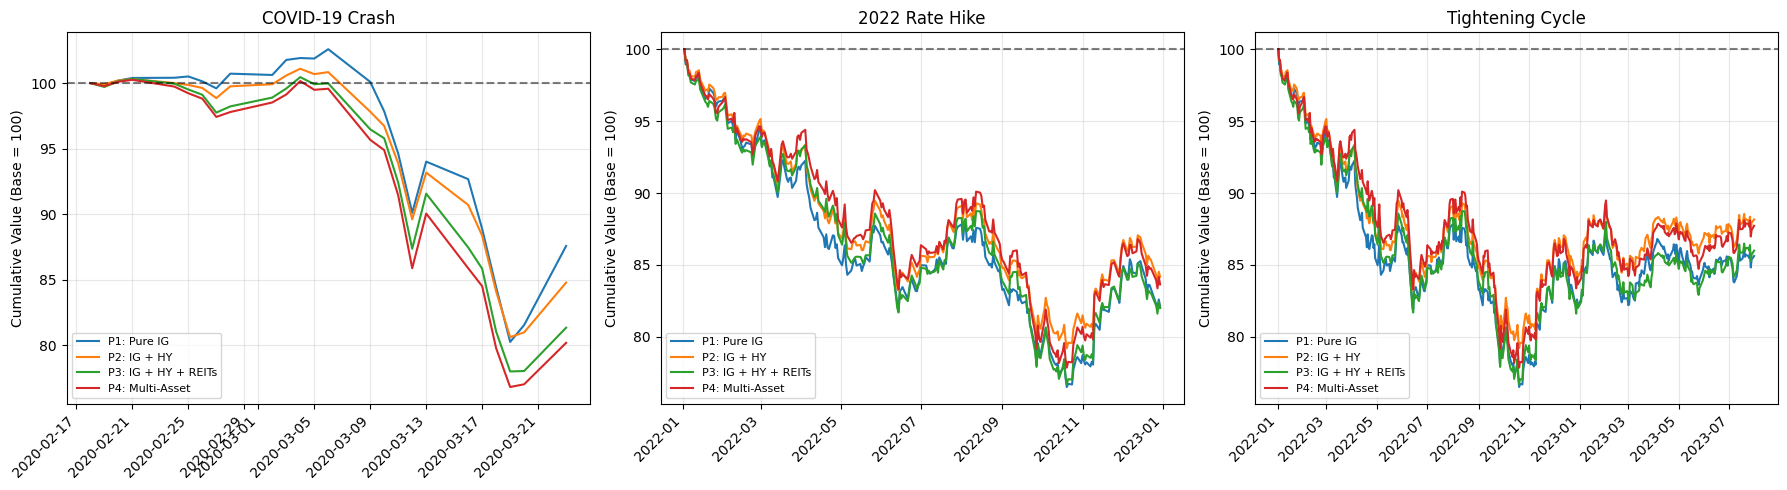

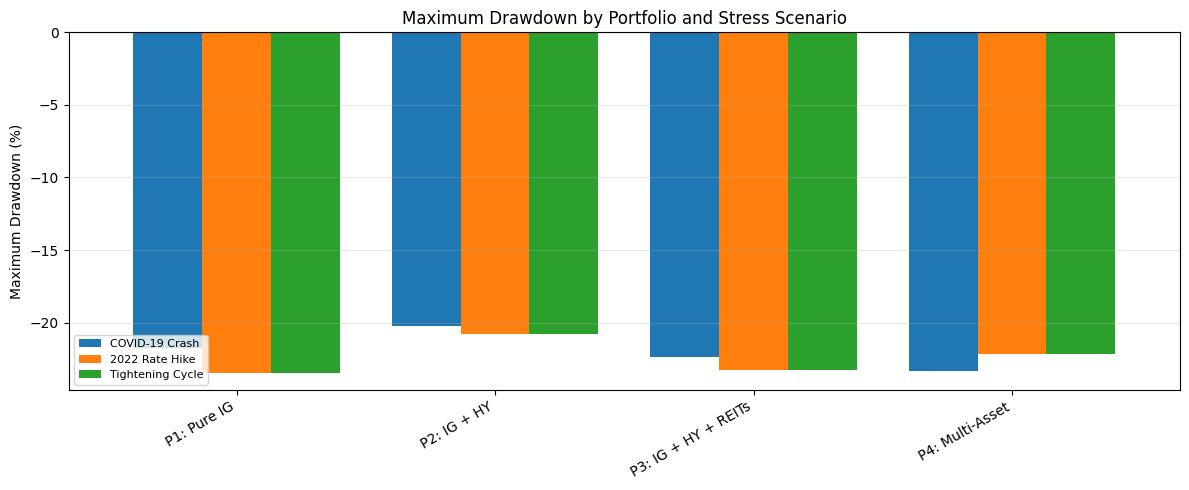


Saved portfolio_returns.parquet and revised stress figures.


In [10]:
# ============================================================
# STEP 3: Portfolio construction and historical stress testing
# Fixed: consistent MDD with initial wealth = 1; clean plots
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Inputs produced by Step 1
returns_daily = pd.read_parquet('daily_returns.parquet').sort_index()
rf_daily = pd.read_parquet('rf_daily.parquet')['RF'].reindex(returns_daily.index).ffill()

portfolios = {
    'P1: Pure IG': {'LQD': 1.00},
    'P2: IG + HY': {'LQD': 0.70, 'HYG': 0.30},
    'P3: IG + HY + REITs': {'LQD': 0.70, 'HYG': 0.15, 'VNQ': 0.15},
    'P4: Multi-Asset': {'LQD': 0.70, 'HYG': 0.10, 'VNQ': 0.10, 'IGF': 0.10},
}

# Daily rebalanced constant-weight portfolios, consistent with original Step 3.
port_returns = pd.DataFrame(index=returns_daily.index)
for name, weights in portfolios.items():
    missing = set(weights) - set(returns_daily.columns)
    if missing:
        raise ValueError(f'Missing ETF return columns for {name}: {sorted(missing)}')
    port_returns[name] = sum(returns_daily[ticker] * weight
                             for ticker, weight in weights.items())

windows_main = {
    'COVID-19 (crash)': ('2020-02-19', '2020-03-23'),
    '2022 Rate Hike': ('2022-01-01', '2022-12-31'),
    'Tightening Cycle': ('2022-01-01', '2023-07-31'),
}
windows_robust = {
    'COVID-19 (wide)': ('2020-02-01', '2020-04-30'),
    'High Inflation': ('2021-01-01', '2023-12-31'),
}


def wealth_and_drawdown(period_returns):
    """Wealth begins at 1 immediately before the first observed return."""
    r = pd.Series(period_returns, dtype=float).dropna()
    if r.empty:
        raise ValueError('No returns in stress window')
    if (r <= -1).any():
        raise ValueError('Returns of -100% or below are invalid for wealth calculation')
    wealth = np.r_[1.0, (1.0 + r.to_numpy()).cumprod()]
    peaks = np.maximum.accumulate(wealth)
    drawdowns = wealth / peaks - 1.0
    return wealth, drawdowns


def performance_metrics(period_returns):
    r = pd.Series(period_returns, dtype=float).dropna()
    fields = ['CumRet(%)', 'AnnVol(%)', 'MaxDD(%)',
              'VaR95(%)', 'CVaR95(%)', 'Sortino']
    if len(r) < 2:
        return {field: np.nan for field in fields}

    wealth, drawdowns = wealth_and_drawdown(r)
    cum_ret = wealth[-1] - 1.0
    ann_vol = r.std(ddof=1) * np.sqrt(252)
    max_dd = drawdowns.min()

    threshold = np.percentile(r, 5)
    tail = r[r <= threshold]
    var95 = -threshold
    cvar95 = -tail.mean() if len(tail) else np.nan

    rf = rf_daily.reindex(r.index)
    if rf.isna().any():
        raise ValueError('Missing daily risk-free rates within a stress window')
    excess = r - rf
    downside = np.minimum(excess, 0.0)
    downside_dev = np.sqrt(np.mean(np.square(downside))) * np.sqrt(252)
    sortino = excess.mean() * 252 / downside_dev if downside_dev > 0 else np.nan

    return {
        'CumRet(%)': round(cum_ret * 100, 2),
        'AnnVol(%)': round(ann_vol * 100, 2),
        'MaxDD(%)': round(max_dd * 100, 2),
        'VaR95(%)': round(var95 * 100, 2),
        'CVaR95(%)': round(cvar95 * 100, 2),
        'Sortino': round(sortino, 3),
    }


def scenario_table(windows):
    tables = {}
    for label, (start, end) in windows.items():
        sub = port_returns.loc[start:end]
        if len(sub) < 2:
            raise ValueError(f'Not enough observations for {label}')
        table = pd.DataFrame({
            name: performance_metrics(sub[name])
            for name in port_returns.columns
        }).T
        tables[label] = table
        print(f'\n--- {label} ({start} -> {end}) | N days: {len(sub)} ---')
        print(table.to_string())
    return tables


print('=' * 90)
print('Main analysis: revised stress windows')
print('=' * 90)
main_tables = scenario_table(windows_main)

print('\n' + '=' * 90)
print('Robustness: wide windows')
print('=' * 90)
robust_tables = scenario_table(windows_robust)

# One line per portfolio. Values begin at 100 immediately before first return.
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
plot_windows = {
    'COVID-19 Crash': windows_main['COVID-19 (crash)'],
    '2022 Rate Hike': windows_main['2022 Rate Hike'],
    'Tightening Cycle': windows_main['Tightening Cycle'],
}
for ax, (label, (start, end)) in zip(axes, plot_windows.items()):
    sub = port_returns.loc[start:end]
    for name in sub.columns:
        wealth, _ = wealth_and_drawdown(sub[name])
        # Synthetic baseline is placed one calendar day before the first return.
        dates = pd.DatetimeIndex([sub.index[0] - pd.Timedelta(days=1)]).append(sub.index)
        ax.plot(dates, wealth * 100, label=name, linewidth=1.5)
    ax.axhline(100, color='black', linestyle='--', alpha=0.5)
    ax.set_title(label)
    ax.set_ylabel('Cumulative Value (Base = 100)')
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)
    ax.tick_params(axis='x', labelrotation=45)
    for tick in ax.get_xticklabels():
        tick.set_ha('right')
fig.tight_layout()
fig.savefig('stress_windows_performance_revised.png', dpi=150, bbox_inches='tight')
plt.show()

# MDD plot uses EXACTLY the same MDD definition as the printed tables.
mdd_df = pd.DataFrame({
    plot_label: main_tables[table_label]['MaxDD(%)']
    for plot_label, table_label in [
        ('COVID-19 Crash', 'COVID-19 (crash)'),
        ('2022 Rate Hike', '2022 Rate Hike'),
        ('Tightening Cycle', 'Tightening Cycle'),
    ]
})
fig, ax = plt.subplots(figsize=(12, 5))
mdd_df.plot(kind='bar', ax=ax, width=0.8)
ax.set_title('Maximum Drawdown by Portfolio and Stress Scenario')
ax.set_ylabel('Maximum Drawdown (%)')
ax.axhline(0, color='black', alpha=0.5)
ax.legend(fontsize=8, loc='lower left')
ax.grid(True, alpha=0.3, axis='y')
plt.xticks(rotation=30, ha='right')
fig.tight_layout()
fig.savefig('max_drawdown_comparison_revised.png', dpi=150, bbox_inches='tight')
plt.show()

port_returns.to_parquet('portfolio_returns.parquet')
print('\nSaved portfolio_returns.parquet and revised stress figures.')


Ledoit-Wolf shrinkage coefficient: 0.045
Mean-CVaR target annual return: 7.06%
Optimal weights (in-sample, framework comparison only)
     MV (Max Sharpe)  MV (Ledoit-Wolf)  Mean-CVaR  Min-Variance  Risk Parity
LQD           0.0000            0.0000     0.0764         0.533       0.3545
HYG           0.8283            0.7226     0.5821         0.467       0.3358
VNQ           0.1717            0.2333     0.3416         0.000       0.1406
IGF           0.0000            0.0441     0.0000         0.000       0.1691

Performance (in-sample; CVaR is monthly historical tail loss):
              MV  MV-LW  Mean-CVaR  Min-Var  Risk Parity
AnnRet(%)  6.420   6.81       7.06    4.880         6.21
AnnVol(%)  8.670   9.39      10.00    6.830         8.82
CVaR95(%)  5.420   5.78       5.98    4.300         5.43
Sharpe     0.583   0.58       0.57    0.515         0.55

Matched-return optimisation (both require >= 1/N expected return):
     Min-Variance (same target)  Min-CVaR (same target)
LQD     

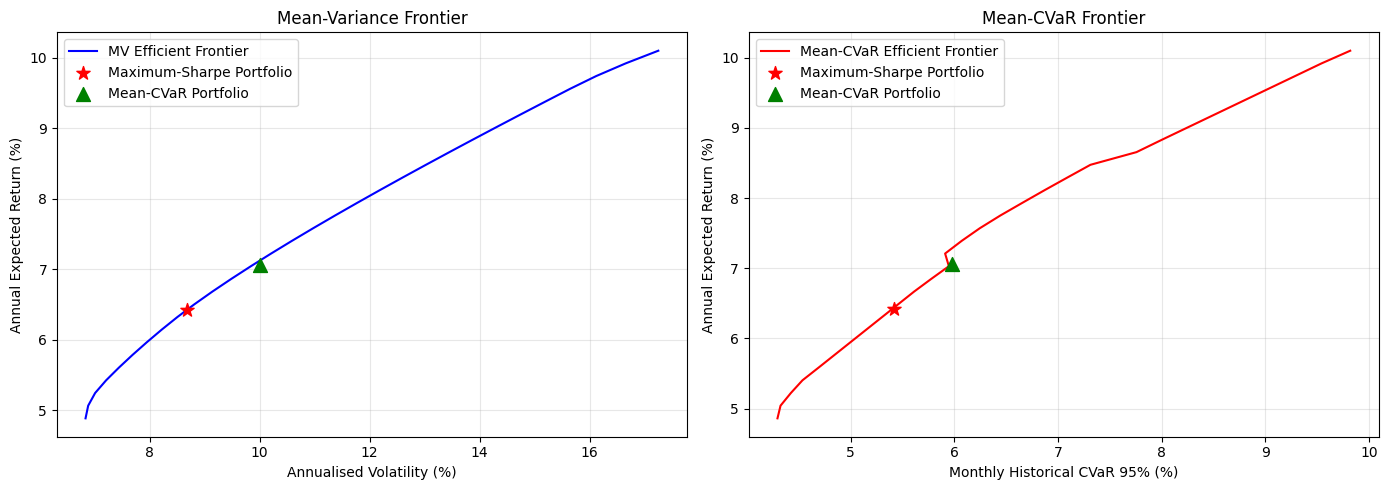


Saved: optimal_weights_static.csv, static_performance.csv, matched_target_weights.csv, matched_target_performance.csv, frontier_comparison.png


In [11]:
# ============================================================
# STEP 4: Static optimization (in-sample)
# - Mean-Variance, Mean-CVaR (RU LP), Min-Var, Risk Parity, Ledoit-Wolf
# NOTE: In-sample, framework comparison only.
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize, linprog
from sklearn.covariance import LedoitWolf

monthly_returns = pd.read_parquet("monthly_returns.parquet")
rf_monthly = pd.read_parquet("rf_monthly.parquet")["RF"].reindex(monthly_returns.index).ffill()
rf_annual = ((1.0 + rf_monthly).prod() ** (12.0 / len(rf_monthly))) - 1.0

assets = ["LQD", "HYG", "VNQ", "IGF"]
R = monthly_returns[assets]
mu = R.mean().values * 12
Sigma = R.cov().values * 12
R_matrix = R.values
N = len(assets); T = len(R)

lw = LedoitWolf().fit(R.values)
Sigma_lw = lw.covariance_ * 12
print(f"Ledoit-Wolf shrinkage coefficient: {lw.shrinkage_:.3f}")

bounds = [(0, 1)] * N
w0 = np.ones(N) / N

def portfolio_vol(w, S):
    return np.sqrt(w @ S @ w)

def portfolio_cvar(w, R_mat, alpha=0.95):
    port = R_mat @ w
    var_t = np.percentile(port, (1 - alpha) * 100)
    tail = port[port <= var_t]
    return -tail.mean() if len(tail) > 0 else 0.0

def neg_sharpe(w, mu_v, S, rf_a):
    vol = portfolio_vol(w, S)
    return -((w @ mu_v) - rf_a) / vol if vol > 1e-10 else 1e6

def optimize_cvar_lp(R_mat, mu_v, alpha=0.95, target=None):
    """Rockafellar-Uryasev LP:
    min theta + 1/((1-alpha)*T) * sum(u_t)
    s.t.  r_t(w) + theta + u_t >= 0, u_t >= 0, sum(w)=1, w>=0, mu'w >= target (opt.)
    Variables: [w (N), theta (1), u (T)]
    """
    T_, N_ = R_mat.shape
    n_vars = N_ + 1 + T_
    c = np.zeros(n_vars); c[N_] = 1.0
    c[N_ + 1:] = 1.0 / ((1 - alpha) * T_)
    A_ub = np.zeros((T_, n_vars))
    A_ub[:, :N_] = -R_mat
    A_ub[:, N_] = -1.0
    A_ub[:, N_ + 1:] = -np.eye(T_)
    b_ub = np.zeros(T_)
    if target is not None:
        A_t = np.zeros((1, n_vars)); A_t[0, :N_] = -mu_v
        A_ub = np.vstack([A_ub, A_t]); b_ub = np.concatenate([b_ub, [-target]])
    A_eq = np.zeros((1, n_vars)); A_eq[0, :N_] = 1.0
    b_eq = np.array([1.0])
    bnds = [(0, 1)] * N_ + [(None, None)] + [(0, None)] * T_
    res = linprog(c, A_ub=A_ub, b_ub=b_ub, A_eq=A_eq, b_eq=b_eq,
                  bounds=bnds, method="highs")
    return res.x[:N_] if res.success else None

# ---------- MV ----------
res_mv = minimize(neg_sharpe, w0, args=(mu, Sigma, rf_annual),
                  method="SLSQP", bounds=bounds,
                  constraints=[{"type": "eq", "fun": lambda w: np.sum(w) - 1}],
                  options={"maxiter": 500, "ftol": 1e-10})
if not res_mv.success:
    raise RuntimeError(f"Static MV optimisation failed: {res_mv.message}")
w_mv = res_mv.x

# ---------- Mean-CVaR ----------
target_return_cvar = float(w0 @ mu)
w_cvar = optimize_cvar_lp(R_matrix, mu, alpha=0.95, target=target_return_cvar)
if w_cvar is None:
    raise RuntimeError("Static Mean-CVaR linear program failed")
print(f"Mean-CVaR target annual return: {target_return_cvar:.2%}")

# ---------- Min-Var ----------
res_minvar = minimize(lambda w: w @ Sigma @ w, w0, method="SLSQP", bounds=bounds,
                      constraints=[{"type": "eq", "fun": lambda w: np.sum(w) - 1}])
if not res_minvar.success:
    raise RuntimeError(f"Minimum variance optimisation failed: {res_minvar.message}")
w_minvar = res_minvar.x

# ---------- Risk Parity ----------
def rp_obj(w, S):
    vol = portfolio_vol(w, S)
    rc = w * ((S @ w) / vol)
    return np.sum((rc - rc.mean()) ** 2)
res_rp = minimize(rp_obj, w0, args=(Sigma,), method="SLSQP", bounds=bounds,
                  constraints=[{"type": "eq", "fun": lambda w: np.sum(w) - 1}])
if not res_rp.success:
    raise RuntimeError(f"Risk parity optimisation failed: {res_rp.message}")
w_rp = res_rp.x

# ---------- MV with Ledoit-Wolf ----------
res_mv_lw = minimize(neg_sharpe, w0, args=(mu, Sigma_lw, rf_annual),
                     method="SLSQP", bounds=bounds,
                     constraints=[{"type": "eq", "fun": lambda w: np.sum(w) - 1}])
if not res_mv_lw.success:
    raise RuntimeError(f"Ledoit-Wolf MV optimisation failed: {res_mv_lw.message}")
w_mv_lw = res_mv_lw.x

# ---------- Matched expected-return comparison: min variance vs min CVaR ----------
# Both optimisations impose the same 1/N expected-return floor.
matched_cons = [
    {"type": "eq", "fun": lambda w: np.sum(w) - 1},
    {"type": "ineq", "fun": lambda w: w @ mu - target_return_cvar},
]
res_matched_mv = minimize(lambda w: w @ Sigma @ w, w0,
                          method="SLSQP", bounds=bounds, constraints=matched_cons,
                          options={"maxiter": 1000, "ftol": 1e-12})
if not res_matched_mv.success:
    raise RuntimeError(f"Matched-target min-variance failed: {res_matched_mv.message}")
w_matched_mv = res_matched_mv.x
assert w_matched_mv @ mu >= target_return_cvar - 1e-7
assert w_cvar @ mu >= target_return_cvar - 1e-7

# ---------- Summary ----------
weight_df = pd.DataFrame({
    "MV (Max Sharpe)":  w_mv.round(4),
    "MV (Ledoit-Wolf)": w_mv_lw.round(4),
    "Mean-CVaR":        w_cvar.round(4),
    "Min-Variance":     w_minvar.round(4),
    "Risk Parity":      w_rp.round(4),
}, index=assets)
print("=" * 70)
print("Optimal weights (in-sample, framework comparison only)")
print("=" * 70)
print(weight_df.to_string())

def perf(w, mu_v, S, R_mat, rf_a):
    port_ret = w @ mu_v
    port_vol = np.sqrt(w @ S @ w)
    port_cvar = portfolio_cvar(w, R_mat)
    return {"AnnRet(%)":  round(port_ret * 100, 2),
            "AnnVol(%)":  round(port_vol * 100, 2),
            "CVaR95(%)":  round(port_cvar * 100, 2),
            "Sharpe":     round((port_ret - rf_a) / port_vol, 3)}

perf_df = pd.DataFrame({
    "MV":          perf(w_mv, mu, Sigma, R_matrix, rf_annual),
    "MV-LW":       perf(w_mv_lw, mu, Sigma, R_matrix, rf_annual),
    "Mean-CVaR":   perf(w_cvar, mu, Sigma, R_matrix, rf_annual),
    "Min-Var":     perf(w_minvar, mu, Sigma, R_matrix, rf_annual),
    "Risk Parity": perf(w_rp, mu, Sigma, R_matrix, rf_annual),
})
print("\nPerformance (in-sample; CVaR is monthly historical tail loss):")
print(perf_df.to_string())

# ---------- Same-target comparison (annual expected-return floor) ----------
matched_weights = pd.DataFrame({
    "Min-Variance (same target)": w_matched_mv,
    "Min-CVaR (same target)": w_cvar,
}, index=assets)
matched_performance = pd.DataFrame({
    "Min-Variance (same target)": perf(w_matched_mv, mu, Sigma, R_matrix, rf_annual),
    "Min-CVaR (same target)": perf(w_cvar, mu, Sigma, R_matrix, rf_annual),
}).T
print("\nMatched-return optimisation (both require >= 1/N expected return):")
print(matched_weights.to_string())
print(matched_performance.to_string())
matched_weights.to_csv("matched_target_weights.csv")
matched_performance.to_csv("matched_target_performance.csv")

# ---------- Efficient frontiers ----------
# Only the efficient (upper) branch of the mean-variance frontier is plotted.
# w_minvar was computed and convergence-checked earlier in this Step.
min_var_return = float(w_minvar @ mu)
max_feasible_return = float(np.max(mu))
if max_feasible_return <= min_var_return + 1e-10:
    raise RuntimeError("No non-degenerate upper efficient branch found")
target_rets = np.linspace(min_var_return, max_feasible_return, 30)

def min_var_for_target(target, mu_v, S):
    cons = [{"type": "eq", "fun": lambda w: np.sum(w) - 1},
            {"type": "eq", "fun": lambda w: w @ mu_v - target}]
    r = minimize(portfolio_vol, w0, args=(S,), method="SLSQP",
                 bounds=bounds, constraints=cons)
    if not r.success:
        return None
    if abs(float(r.x @ mu_v) - target) > 1e-5:
        return None
    return r.x

# The minimum-CVaR frontier also starts at its global minimum-risk point.
w_global_min_cvar = optimize_cvar_lp(R_matrix, mu, alpha=0.95, target=None)
if w_global_min_cvar is None:
    raise RuntimeError("Global minimum-CVaR LP failed")
min_cvar_return = float(w_global_min_cvar @ mu)
print(f"Global minimum-CVaR expected annual return: {min_cvar_return:.2%}")
cvar_target_rets = np.linspace(min_cvar_return, max_feasible_return, 30)

frontier_mv, frontier_cvar = [], []
for t in target_rets:
    wv = min_var_for_target(t, mu, Sigma)
    if wv is not None:
        frontier_mv.append((portfolio_vol(wv, Sigma), t))

for t in cvar_target_rets:
    wc = optimize_cvar_lp(R_matrix, mu, alpha=0.95, target=t)
    if wc is not None and float(wc @ mu) >= t - 1e-6:
        frontier_cvar.append((portfolio_cvar(wc, R_matrix), t))

if not frontier_mv or not frontier_cvar:
    raise RuntimeError("Unable to construct one or both frontiers")
frontier_mv = np.array(frontier_mv)
frontier_cvar = np.array(frontier_cvar)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(frontier_mv[:, 0] * 100, frontier_mv[:, 1] * 100, "b-", label="MV Efficient Frontier")
axes[0].scatter(portfolio_vol(w_mv, Sigma) * 100, (w_mv @ mu) * 100,
                color="red", s=100, marker="*", zorder=5, label="Maximum-Sharpe Portfolio")
axes[0].scatter(portfolio_vol(w_cvar, Sigma) * 100, (w_cvar @ mu) * 100,
                color="green", s=100, marker="^", zorder=5, label="Mean-CVaR Portfolio")
axes[0].set_xlabel("Annualised Volatility (%)"); axes[0].set_ylabel("Annual Expected Return (%)")
axes[0].set_title("Mean-Variance Frontier"); axes[0].legend(); axes[0].grid(True, alpha=0.3)

axes[1].plot(frontier_cvar[:, 0] * 100, frontier_cvar[:, 1] * 100, "r-", label="Mean-CVaR Efficient Frontier")
axes[1].scatter(portfolio_cvar(w_mv, R_matrix) * 100, (w_mv @ mu) * 100,
                color="red", s=100, marker="*", zorder=5, label="Maximum-Sharpe Portfolio")
axes[1].scatter(portfolio_cvar(w_cvar, R_matrix) * 100, (w_cvar @ mu) * 100,
                color="green", s=100, marker="^", zorder=5, label="Mean-CVaR Portfolio")
axes[1].set_xlabel("Monthly Historical CVaR 95% (%)"); axes[1].set_ylabel("Annual Expected Return (%)")
axes[1].set_title("Mean-CVaR Frontier"); axes[1].legend(); axes[1].grid(True, alpha=0.3)
plt.tight_layout(); plt.savefig("frontier_comparison.png", dpi=200, bbox_inches="tight"); plt.show()

weight_df.to_csv("optimal_weights_static.csv")
perf_df.to_csv("static_performance.csv")
print("\nSaved: optimal_weights_static.csv, static_performance.csv, matched_target_weights.csv, matched_target_performance.csv, frontier_comparison.png")



Main analysis: rolling window = 60 months
Out-of-sample performance (60M window, with trading cost)
                  AnnRet(%)  AnnVol(%)  Sharpe  MaxDD(%)  VaR95(%)  CVaR95(%)
MV Optimal             2.61      11.01   0.060    -34.89      4.88       7.09
CVaR Optimal           2.68       9.02   0.081    -25.75      4.75       6.21
1/N Equal Weight       5.17      10.76   0.299    -19.20      4.18       6.73
MV Net of Cost         2.34      11.03   0.036    -35.32      4.92       7.12
CVaR Net of Cost       2.33       9.04   0.042    -26.38      4.86       6.26
1/N Net of Cost        5.15      10.76   0.297    -19.22      4.18       6.74

Avg turnover: MV = 22.59%, CVaR = 29.44%
Avg 1/N turnover: 1.49%
Annualised trading cost: MV ~= 0.27%, CVaR ~= 0.35%, 1/N ~= 0.02%

Rolling-window robustness comparison
                       AnnRet(%)  AnnVol(%)  Sharpe  MaxDD(%)  VaR95(%)  CVaR95(%)
W36_MV Optimal              3.85      10.69   0.205    -30.83      4.79       6.56
W36_CVaR Optimal  

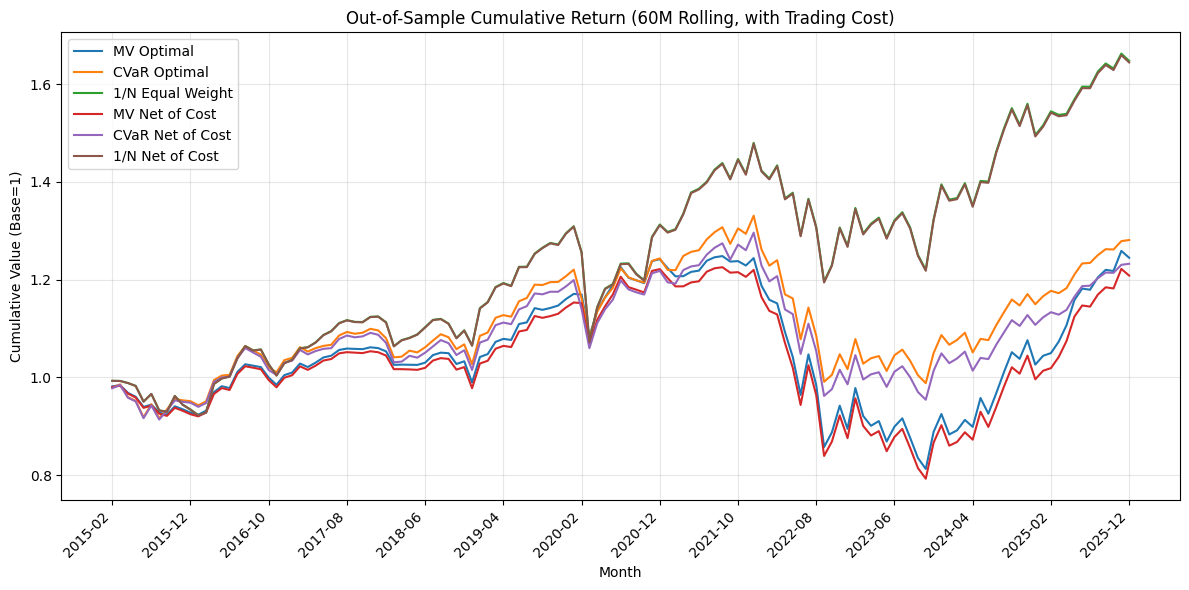

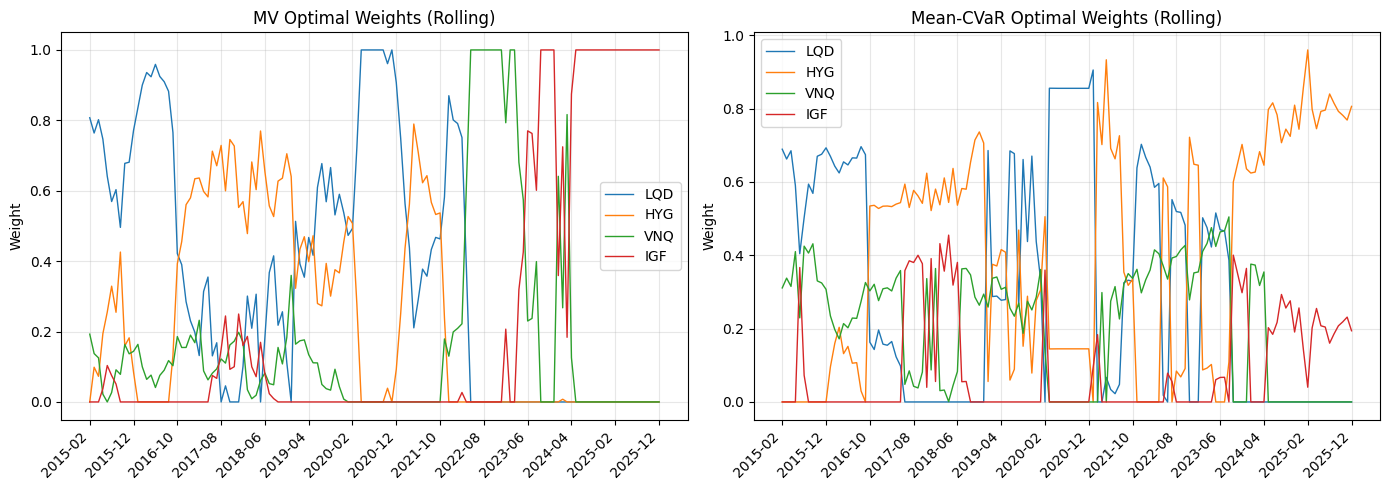


Saved OOS results.


In [6]:
# ============================================================
# STEP 5: Rolling out-of-sample optimization
# - CVaR via LP
# - Includes turnover and 10bps one-way transaction costs
# - Robustness across 36 / 60 / 120-month windows
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize, linprog
import warnings
warnings.filterwarnings("ignore")

monthly_returns = pd.read_parquet("monthly_returns.parquet")
rf_monthly_all = pd.read_parquet("rf_monthly.parquet")["RF"].reindex(monthly_returns.index).ffill()
assets = ["LQD", "HYG", "VNQ", "IGF"]
R_all = monthly_returns[assets]
N = len(assets)
w0 = np.ones(N) / N
bounds = [(0, 1)] * N

def portfolio_vol(w, S):
    return np.sqrt(w @ S @ w)

def portfolio_cvar(w, R_mat, alpha=0.95):
    port = R_mat @ w
    var_t = np.percentile(port, (1 - alpha) * 100)
    tail = port[port <= var_t]
    return -tail.mean() if len(tail) > 0 else 0.0

def optimize_cvar_lp(R_mat, mu_v, alpha=0.95, target=None):
    T_, N_ = R_mat.shape
    n_vars = N_ + 1 + T_
    c = np.zeros(n_vars); c[N_] = 1.0
    c[N_ + 1:] = 1.0 / ((1 - alpha) * T_)
    A_ub = np.zeros((T_, n_vars))
    A_ub[:, :N_] = -R_mat; A_ub[:, N_] = -1.0
    A_ub[:, N_ + 1:] = -np.eye(T_)
    b_ub = np.zeros(T_)
    if target is not None:
        A_t = np.zeros((1, n_vars)); A_t[0, :N_] = -mu_v
        A_ub = np.vstack([A_ub, A_t]); b_ub = np.concatenate([b_ub, [-target]])
    A_eq = np.zeros((1, n_vars)); A_eq[0, :N_] = 1.0; b_eq = np.array([1.0])
    bnds = [(0, 1)] * N_ + [(None, None)] + [(0, None)] * T_
    res = linprog(c, A_ub=A_ub, b_ub=b_ub, A_eq=A_eq, b_eq=b_eq,
                  bounds=bnds, method="highs")
    return res.x[:N_] if res.success else None

def optimize_mv(mu_v, S, rf_a):
    def neg_sharpe(w):
        vol = portfolio_vol(w, S)
        return -((w @ mu_v) - rf_a) / vol if vol > 1e-10 else 1e6
    res = minimize(neg_sharpe, w0, method="SLSQP", bounds=bounds,
                   constraints=[{"type": "eq", "fun": lambda w: np.sum(w) - 1}],
                   options={"maxiter": 500, "ftol": 1e-10})
    if not res.success:
        raise RuntimeError(f"Rolling MV optimisation failed: {res.message}")
    return res.x

def run_rolling_oos(window, tc_rate=0.0010):
    """Monthly rebalance; turnover = purchases + sales, using drifted pre-trade weights.

    Initial portfolio is 1/N immediately before the first OOS rebalance;
    initial reallocation costs are included. All strategies (including 1/N)
    are charged the same 10 bps per dollar traded. Returns are simple returns.
    """
    T = len(R_all)
    if not 12 <= window < T:
        raise ValueError("Invalid rolling estimation window")
    weights_mv, weights_cvar, weights_1n = {}, {}, {}
    gross = {"MV Optimal": [], "CVaR Optimal": [], "1/N Equal Weight": []}
    net = {"MV Net of Cost": [], "CVaR Net of Cost": [], "1/N Net of Cost": []}
    turnover = {"MV": [], "CVaR": [], "1/N": []}
    dates = []
    # Drifted weights at the START of the first OOS month; equal-weight seed.
    pretrade = {"MV": w0.copy(), "CVaR": w0.copy(), "1/N": w0.copy()}
    for t in range(window, T):
        Rw = R_all.iloc[t-window:t]
        mu_w = Rw.mean().values * 12
        Sw = Rw.cov().values * 12
        rf_w = rf_monthly_all.reindex(Rw.index)
        if rf_w.isna().any():
            raise ValueError(f"Missing risk-free rate in estimation window ending {Rw.index[-1]}")
        rf_a = (1.0 + rf_w).prod() ** (12.0 / len(rf_w)) - 1.0
        w_mv = optimize_mv(mu_w, Sw, rf_a)
        w_cv = optimize_cvar_lp(Rw.values, mu_w, alpha=0.95,
                                target=float(w0 @ mu_w))
        if w_cv is None:
            raise RuntimeError(f"Rolling Mean-CVaR LP failed at {R_all.index[t]}")
        allocations = {"MV": w_mv, "CVaR": w_cv, "1/N": w0.copy()}
        realised = R_all.iloc[t].values
        dates.append(R_all.index[t])
        for name, target_w in allocations.items():
            if not np.isclose(target_w.sum(), 1.0, atol=1e-6) or np.min(target_w) < -1e-7:
                raise ValueError(f"Invalid {name} weights at {R_all.index[t]}")
            turn = float(np.abs(target_w - pretrade[name]).sum())
            r_g = float(target_w @ realised)
            r_n = r_g - tc_rate * turn
            turnover[name].append(turn)
            gross[{"MV":"MV Optimal", "CVaR":"CVaR Optimal", "1/N":"1/N Equal Weight"}[name]].append(r_g)
            net[{"MV":"MV Net of Cost", "CVaR":"CVaR Net of Cost", "1/N":"1/N Net of Cost"}[name]].append(r_n)
            # Buy-and-hold drift of weights over the month, before next rebalance.
            pretrade[name] = target_w * (1.0 + realised) / (1.0 + r_g)
        weights_mv[R_all.index[t]] = w_mv
        weights_cvar[R_all.index[t]] = w_cv
        weights_1n[R_all.index[t]] = w0.copy()
    oos = pd.DataFrame({**gross, **net}, index=dates)
    return oos, weights_mv, weights_cvar, turnover["MV"], turnover["CVaR"], turnover["1/N"]

def oos_performance(returns, rf_m):
    ann_ret = returns.mean() * 12 * 100
    ann_vol = returns.std() * np.sqrt(12) * 100
    rf_s = rf_m.reindex(returns.index).ffill()
    excess = returns - rf_s
    sharpe = (excess.mean() * 12) / (returns.std() * np.sqrt(12))
    cum = (1 + returns).cumprod()
    mdd = ((cum / cum.cummax()) - 1).min() * 100
    var_t = np.percentile(returns, 5)
    var95 = -var_t * 100
    tail = returns[returns <= var_t]
    cvar95 = -tail.mean() * 100 if len(tail) > 0 else np.nan
    return {"AnnRet(%)": round(ann_ret, 2),
            "AnnVol(%)": round(ann_vol, 2),
            "Sharpe":    round(sharpe, 3),
            "MaxDD(%)":  round(mdd, 2),
            "VaR95(%)":  round(var95, 2),
            "CVaR95(%)": round(cvar95, 2)}

print("Main analysis: rolling window = 60 months")
oos_returns, weights_mv, weights_cvar, turn_mv, turn_cv, turn_1n = run_rolling_oos(window=60, tc_rate=0.0010)

perf_df = pd.DataFrame({
    col: oos_performance(oos_returns[col], rf_monthly_all)
    for col in oos_returns.columns
}).T
print("=" * 70)
print("Out-of-sample performance (60M window, with trading cost)")
print("=" * 70)
print(perf_df.to_string())
print(f"\nAvg turnover: MV = {np.mean(turn_mv):.2%}, CVaR = {np.mean(turn_cv):.2%}")
print(f"Avg 1/N turnover: {np.mean(turn_1n):.2%}")
print(f"Annualised trading cost: MV ~= {np.mean(turn_mv)*0.001*12:.2%}, CVaR ~= {np.mean(turn_cv)*0.001*12:.2%}, 1/N ~= {np.mean(turn_1n)*0.001*12:.2%}")

robust_perf = {}
robust_common_perf = {}
common_start = R_all.index[120]  # identical OOS calendar months for all lookback windows
for w_len in [36, 60, 120]:
    if w_len >= len(R_all) - 12:
        continue
    oos_w, _, _, _, _, _ = run_rolling_oos(window=w_len, tc_rate=0.0010)
    for col in oos_w.columns:
        robust_perf[f"W{w_len}_{col}"] = oos_performance(oos_w[col], rf_monthly_all)
        aligned = oos_w.loc[oos_w.index >= common_start, col]
        if len(aligned):
            robust_common_perf[f"W{w_len}_{col}"] = oos_performance(aligned, rf_monthly_all)

robust_df = pd.DataFrame(robust_perf).T
print("\n" + "=" * 70)
print("Rolling-window robustness comparison")
print("=" * 70)
print(robust_df.to_string())
robust_common_df = pd.DataFrame(robust_common_perf).T
print(f"\nCommon-period robustness (all windows evaluated from {common_start}):")
print(robust_common_df.to_string())

fig, ax = plt.subplots(figsize=(12, 6))
for col in oos_returns.columns:
    cum = (1 + oos_returns[col]).cumprod()
    ax.plot(range(len(cum)), cum.values, label=col, linewidth=1.5)
ax.set_title("Out-of-Sample Cumulative Return (60M Rolling, with Trading Cost)")
ax.set_ylabel("Cumulative Value (Base=1)"); ax.set_xlabel("Month")
ax.legend(); ax.grid(True, alpha=0.3)
step = max(1, len(oos_returns) // 12)
ax.set_xticks(range(0, len(oos_returns), step))
ax.set_xticklabels([str(d) for d in oos_returns.index[::step]], rotation=45, ha="right")
plt.tight_layout(); plt.savefig("oos_cumulative_return.png", dpi=150); plt.show()

w_mv_df = pd.DataFrame.from_dict(weights_mv, orient="index", columns=assets)
w_cvar_df = pd.DataFrame.from_dict(weights_cvar, orient="index", columns=assets)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for col in assets:
    axes[0].plot(range(len(w_mv_df)), w_mv_df[col].values, label=col, linewidth=1)
axes[0].set_title("MV Optimal Weights (Rolling)"); axes[0].set_ylabel("Weight")
axes[0].legend(); axes[0].grid(True, alpha=0.3)
axes[0].set_xticks(range(0, len(w_mv_df), step))
axes[0].set_xticklabels([str(d) for d in w_mv_df.index[::step]], rotation=45, ha="right")

for col in assets:
    axes[1].plot(range(len(w_cvar_df)), w_cvar_df[col].values, label=col, linewidth=1)
axes[1].set_title("Mean-CVaR Optimal Weights (Rolling)"); axes[1].set_ylabel("Weight")
axes[1].legend(); axes[1].grid(True, alpha=0.3)
axes[1].set_xticks(range(0, len(w_cvar_df), step))
axes[1].set_xticklabels([str(d) for d in w_cvar_df.index[::step]], rotation=45, ha="right")
plt.tight_layout(); plt.savefig("oos_weights_evolution.png", dpi=150); plt.show()

oos_returns.to_parquet("oos_returns.parquet")
w_mv_df.to_csv("oos_weights_mv.csv")
w_cvar_df.to_csv("oos_weights_cvar.csv")
perf_df.to_csv("oos_performance.csv")
robust_df.to_csv("oos_robustness_windows.csv")
robust_common_df.to_csv("oos_robustness_common_period.csv")
pd.DataFrame({"MV": turn_mv, "CVaR": turn_cv, "1/N": turn_1n},
             index=oos_returns.index).to_csv("oos_turnover.csv")
print("\nSaved OOS results.")



Aligned factor sample: 2010-02 -> 2025-12 | N=191 months

CAPM: OLS coefficients with Newey-West HAC (3 lags)
      Model  Alpha (monthly %)  Alpha HAC t-stat  Alpha HAC p-value      R2  Adjusted R2    N  Mkt-RF  SMB  HML  Delta_TS  Delta_CS
Asset                                                                                                                              
LQD    CAPM            -0.0130           -0.0803             0.9360  0.2142       0.2100  191  0.2284  NaN  NaN       NaN       NaN
HYG    CAPM            -0.0846           -0.9164             0.3595  0.6270       0.6251  191  0.4024  NaN  NaN       NaN       NaN
VNQ    CAPM            -0.1976           -0.7694             0.4416  0.5228       0.5203  191  0.8385  NaN  NaN       NaN       NaN
IGF    CAPM            -0.2405           -0.9928             0.3208  0.5758       0.5736  191  0.7415  NaN  NaN       NaN       NaN

FF3: OLS coefficients with Newey-West HAC (3 lags)
      Model  Alpha (monthly %)  Alpha HAC t-st

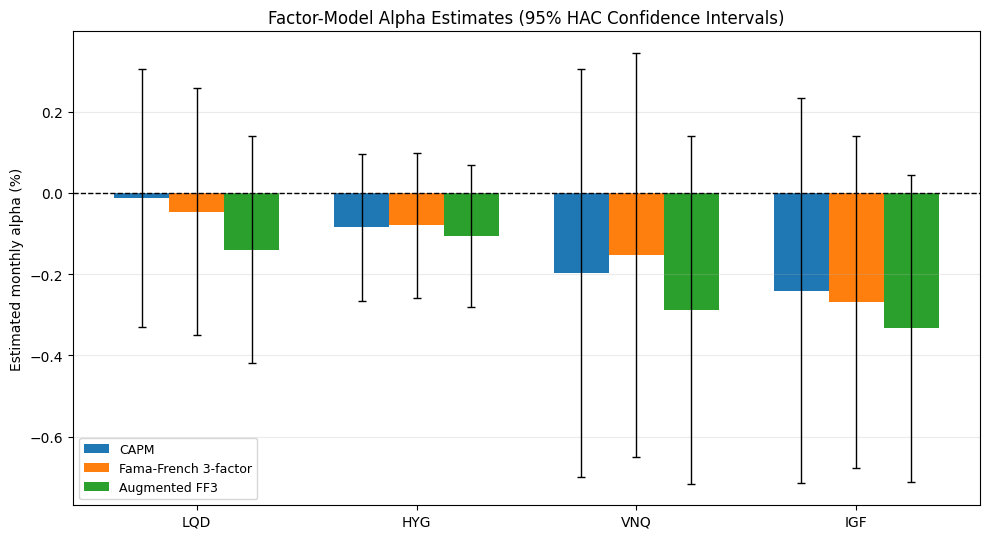

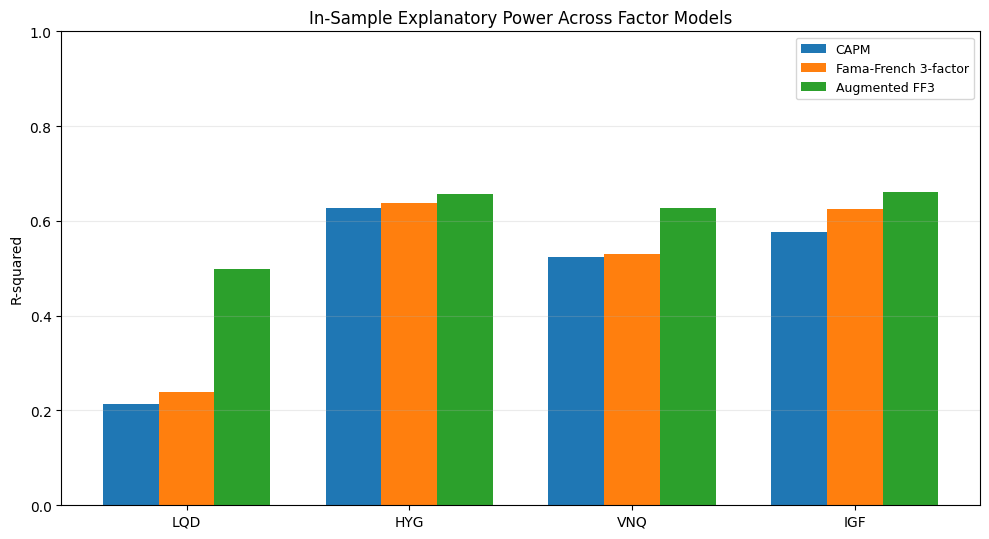


Saved: factor_model_summary.csv, factor_hac_full_inference.csv, 
capm_results.csv, ff3_results.csv, augmented_factor_results.csv,
factor_alpha_comparison.png, factor_r2_comparison.png
Note: Delta_TS and Delta_CS are changes in yield spreads (decimal yield units),
not the original Fama-French traded bond factors. Coefficients are scale-dependent.


In [13]:
# ============================================================
# STEP 6 — FACTOR MODEL ANALYSIS (FINAL)
# CAPM / Fama-French 3-factor / FF3 + bond-market state variables
# OLS coefficients; Newey-West HAC inference (3 monthly lags)
# Input: monthly_returns.parquet from Step 1 (decimal monthly returns)
# ============================================================
import datetime as dt
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from pandas_datareader import data as web

ASSETS = ["LQD", "HYG", "VNQ", "IGF"]
START = dt.datetime(2010, 1, 1)
END = dt.datetime(2026, 1, 1)
HAC_LAGS = 3
OUT = Path(".")

monthly_returns = pd.read_parquet("monthly_returns.parquet")
if not isinstance(monthly_returns.index, pd.PeriodIndex):
    monthly_returns.index = pd.to_datetime(monthly_returns.index).to_period("M")
monthly_returns = monthly_returns.sort_index()
if not set(ASSETS).issubset(monthly_returns.columns):
    raise ValueError("Step 1 monthly_returns.parquet must contain LQD, HYG, VNQ and IGF")

# French monthly returns and risk-free rates are expressed in percent; convert to decimals.
ff = web.DataReader("F-F_Research_Data_Factors", "famafrench", start=START, end=END)[0]
if not isinstance(ff.index, pd.PeriodIndex):
    ff.index = pd.to_datetime(ff.index).to_period("M")
ff = ff[["Mkt-RF", "SMB", "HML", "RF"]].astype(float) / 100.0

# FRED yields are in percent per annum. Convert to decimal yields before differencing.
fred = web.DataReader(["DGS10", "DGS1", "BAA", "AAA"], "fred", start=START, end=END)
fred = fred.sort_index().ffill().resample("ME").last()
fred.index = fred.index.to_period("M")
term_spread = (fred["DGS10"] - fred["DGS1"]) / 100.0
credit_spread = (fred["BAA"] - fred["AAA"]) / 100.0
state = pd.DataFrame({
    "Delta_TS": term_spread.diff(),
    "Delta_CS": credit_spread.diff(),
})

# Use one common, complete monthly sample across all three model specifications.
data = monthly_returns[ASSETS].join(ff, how="inner").join(state, how="inner").dropna()
if len(data) < 36:
    raise ValueError(f"Insufficient aligned monthly observations: {len(data)}")
print(f"Aligned factor sample: {data.index[0]} -> {data.index[-1]} | N={len(data)} months")
R_excess = data[ASSETS].sub(data["RF"], axis=0)

SPECS = {
    "CAPM": ["Mkt-RF"],
    "FF3": ["Mkt-RF", "SMB", "HML"],
    "Augmented": ["Mkt-RF", "SMB", "HML", "Delta_TS", "Delta_CS"],
}
models = {}
rows = []
inference_rows = []

for model_name, factor_names in SPECS.items():
    X = sm.add_constant(data[factor_names], has_constant="add")
    for asset in ASSETS:
        model = sm.OLS(R_excess[asset], X, missing="raise").fit(
            cov_type="HAC", cov_kwds={"maxlags": HAC_LAGS}
        )
        models[(model_name, asset)] = model
        row = {
            "Model": model_name, "Asset": asset,
            "Alpha (monthly %)": model.params["const"] * 100,
            "Alpha HAC t-stat": model.tvalues["const"],
            "Alpha HAC p-value": model.pvalues["const"],
            "R2": model.rsquared,
            "Adjusted R2": model.rsquared_adj,
            "N": int(model.nobs),
        }
        for name in factor_names:
            row[name] = model.params[name]
        rows.append(row)
        ci = model.conf_int(alpha=0.05)
        for name in model.params.index:
            inference_rows.append({
                "Model": model_name, "Asset": asset, "Factor": name,
                "Coefficient": model.params[name],
                "HAC SE": model.bse[name],
                "HAC t-stat": model.tvalues[name],
                "HAC p-value": model.pvalues[name],
                "CI 95% lower": ci.loc[name, 0],
                "CI 95% upper": ci.loc[name, 1],
                "R2": model.rsquared,
                "Adjusted R2": model.rsquared_adj,
                "N observations": int(model.nobs),
            })

summary = pd.DataFrame(rows)
inference = pd.DataFrame(inference_rows)
summary.to_csv(OUT / "factor_model_summary.csv", index=False)
inference.to_csv(OUT / "factor_hac_full_inference.csv", index=False)
for spec, filename in [("CAPM", "capm_results.csv"), ("FF3", "ff3_results.csv"),
                       ("Augmented", "augmented_factor_results.csv")]:
    subset = summary[summary["Model"] == spec].set_index("Asset")
    subset.to_csv(OUT / filename)
    print("\n" + "=" * 76)
    print(f"{spec}: OLS coefficients with Newey-West HAC ({HAC_LAGS} lags)")
    print("=" * 76)
    print(subset.round(4).to_string())

print("\nComplete HAC inference (all coefficients):")
print(inference.round(5).to_string(index=False))

# Plot monthly alpha estimates with 95% HAC confidence intervals.
# A confidence interval crossing zero indicates no significance at the 5% level.
fig, ax = plt.subplots(figsize=(10, 5.5))
x = np.arange(len(ASSETS))
width = 0.25
for j, (spec, label) in enumerate([
    ("CAPM", "CAPM"), ("FF3", "Fama-French 3-factor"),
    ("Augmented", "Augmented FF3")
]):
    estimates = []
    lower = []
    upper = []
    for asset in ASSETS:
        model = models[(spec, asset)]
        ci = model.conf_int().loc["const"] * 100
        estimates.append(model.params["const"] * 100)
        lower.append(model.params["const"] * 100 - ci.iloc[0])
        upper.append(ci.iloc[1] - model.params["const"] * 100)
    xpos = x + (j - 1) * width
    ax.bar(xpos, estimates, width=width, label=label)
    ax.errorbar(xpos, estimates, yerr=np.array([lower, upper]),
                fmt="none", ecolor="black", capsize=3, linewidth=1)
ax.axhline(0, color="black", linestyle="--", linewidth=1)
ax.set_xticks(x, ASSETS)
ax.set_ylabel("Estimated monthly alpha (%)")
ax.set_title("Factor-Model Alpha Estimates (95% HAC Confidence Intervals)")
ax.legend(fontsize=9)
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
fig.savefig(OUT / "factor_alpha_comparison.png", dpi=200, bbox_inches="tight")
plt.show()

# Plot R-squared for all three models (in-sample fit, not predictive performance).
fig, ax = plt.subplots(figsize=(10, 5.5))
for j, (spec, label) in enumerate([
    ("CAPM", "CAPM"), ("FF3", "Fama-French 3-factor"),
    ("Augmented", "Augmented FF3")
]):
    vals = [models[(spec, asset)].rsquared for asset in ASSETS]
    ax.bar(x + (j - 1) * width, vals, width=width, label=label)
ax.set_xticks(x, ASSETS)
ax.set_ylim(0, 1)
ax.set_ylabel("R-squared")
ax.set_title("In-Sample Explanatory Power Across Factor Models")
ax.legend(fontsize=9)
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
fig.savefig(OUT / "factor_r2_comparison.png", dpi=200, bbox_inches="tight")
plt.show()

print("\nSaved: factor_model_summary.csv, factor_hac_full_inference.csv, ")
print("capm_results.csv, ff3_results.csv, augmented_factor_results.csv,")
print("factor_alpha_comparison.png, factor_r2_comparison.png")
print("Note: Delta_TS and Delta_CS are changes in yield spreads (decimal yield units),")
print("not the original Fama-French traded bond factors. Coefficients are scale-dependent.")


STEP 7.1  Daily factor betas (OLS, Newey-West HAC 5 lags)
          units: % of daily return per +1.0 pct-point rise in 10y-1y spread
     beta_DTS  t_DTS  beta_SPY         t_SPY     R2
LQD    -6.463 -15.34     0.146  7.890000e+00  0.403
HYG    -1.126  -6.19     0.381  2.813000e+01  0.595
VNQ    -3.142  -7.03     0.922  2.412000e+01  0.573
IGF    -0.289  -0.83     0.810  2.439000e+01  0.662
TLT   -15.278 -20.59    -0.117 -5.880000e+00  0.616
SPY    -0.000 -13.37     1.000  4.582073e+16  1.000

STEP 7.2  Sleeve weights (control sleeves carry NO credit risk)
      HYG (beta-matched)  VNQ (beta-matched)  IGF (beta-matched)  HYG (duration-only)  VNQ (duration-only)  IGF (duration-only)
TLT                0.074               0.206               0.019                0.074                0.206                0.019
SPY                0.390               0.946               0.812                0.000                0.000                0.000
CASH               0.537              -0.152         

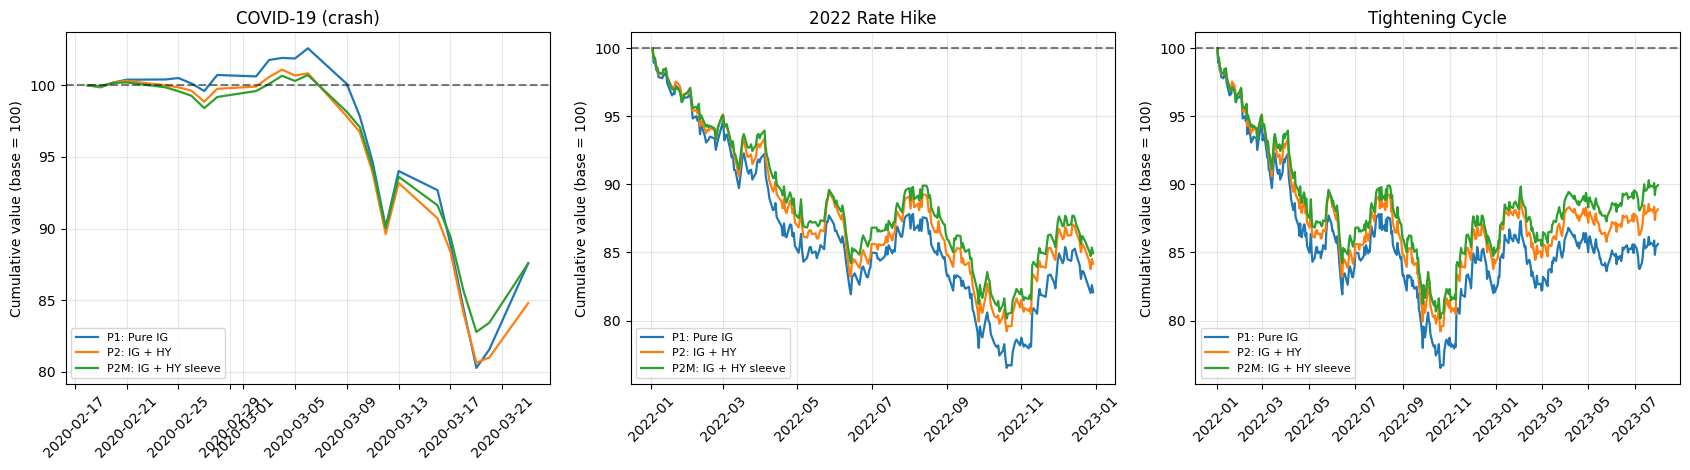


Saved: step7_control_diff.csv, step7_control_bootstrap.csv,
       step7_stress_*.csv, step7_factor_matched_control.png


In [1]:
# =====================================================================
# STEP 7 (NEW)  Factor-matched control portfolios
#
# QUESTION THIS ANSWERS
#   P2 = 70% LQD + 30% HYG.  Compared with P1 (100% LQD), P2 holds 30%
#   LESS duration exposure.  So is P2's advantage over P1 a *credit
#   diversification* effect, or just a *duration / equity-beta* effect?
#
#   Fix: build a credit-free sleeve that replicates HYG's factor
#   exposures (term-spread beta AND equity beta) using TLT + SPY + cash.
#   Replace HYG by that sleeve -> P2M.  If P2 ~ P2M, the "benefit" is
#   factor exposure, not asset-class diversification.
#
# PAPER EDITS
#   §3.3   new sub-section: factor-matched control portfolios
#   §4.3   new comparison table (P1 / P2 / P2M / P2D)
#   §4.3.4 rewrite the "duration vs credit" interpretation with numbers
#   §5.1   conclusion wording
#
# NEEDS: daily_returns.parquet, rf_daily.parquet   (from Step 1)
# =====================================================================
import datetime as dt

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from pandas_datareader import data as web

daily_returns = pd.read_parquet("daily_returns.parquet").sort_index()
rf_daily = pd.read_parquet("rf_daily.parquet")["RF"].reindex(daily_returns.index).ffill()

# ---------- 7.1  Daily change in the 10y-1y term spread (pct points) ----------
START, END = dt.datetime(2010, 1, 1), dt.datetime(2026, 1, 1)
yields = web.DataReader(["DGS10", "DGS1"], "fred", start=START, end=END).sort_index().ffill()
term_level = (yields["DGS10"] - yields["DGS1"]).reindex(daily_returns.index).ffill()
DTS = term_level.diff()            # +1.0 == +100 bp

rets_pct = daily_returns * 100.0   # so coefficients read as "% return per 1 pct-point"


def _ols(col, lags=5):
    X = sm.add_constant(pd.DataFrame({"DTS": DTS, "SPY": rets_pct["SPY"]}))
    return sm.OLS(rets_pct[col], X, missing="drop").fit(
        cov_type="HAC", cov_kwds={"maxlags": lags})


beta_tbl = {}
for c in ["LQD", "HYG", "VNQ", "IGF", "TLT", "SPY"]:
    m = _ols(c)
    beta_tbl[c] = {
        "beta_DTS": round(m.params["DTS"], 3),
        "t_DTS": round(m.tvalues["DTS"], 2),
        "beta_SPY": round(m.params["SPY"], 3),
        "t_SPY": round(m.tvalues["SPY"], 2),
        "R2": round(m.rsquared, 3),
    }
betas = pd.DataFrame(beta_tbl).T

print("=" * 88)
print("STEP 7.1  Daily factor betas (OLS, Newey-West HAC 5 lags)")
print("          units: % of daily return per +1.0 pct-point rise in 10y-1y spread")
print("=" * 88)
print(betas.to_string())


# ---------- 7.2  Credit-free factor-mimicking sleeve (TLT / SPY / cash) ----------
# Two beta constraints (DTS, SPY) + full investment => exactly identified 3x3 solve.
def sleeve_weights(target):
    A = np.array([[betas.loc["TLT", "beta_DTS"], betas.loc["SPY", "beta_DTS"], 0.0],
                  [betas.loc["TLT", "beta_SPY"], betas.loc["SPY", "beta_SPY"], 0.0],
                  [1.0, 1.0, 1.0]])
    b = np.array([betas.loc[target, "beta_DTS"],
                  betas.loc[target, "beta_SPY"],
                  1.0])
    return np.linalg.solve(A, b)


# duration-only sleeve (TLT + cash), equity beta deliberately left at zero
def sleeve_weights_dts_only(target):
    ratio = betas.loc[target, "beta_DTS"] / betas.loc["TLT", "beta_DTS"]
    return np.array([ratio, 0.0, 1.0 - ratio])


sleeve_w = {a: sleeve_weights(a) for a in ["HYG", "VNQ", "IGF"]}
sleeve_w_dts = {a: sleeve_weights_dts_only(a) for a in ["HYG", "VNQ", "IGF"]}

sw_tbl = pd.DataFrame({**{f"{a} (beta-matched)": sleeve_w[a] for a in sleeve_w},
                       **{f"{a} (duration-only)": sleeve_w_dts[a] for a in sleeve_w_dts}},
                      index=["TLT", "SPY", "CASH"]).round(3)
print("\n" + "=" * 88)
print("STEP 7.2  Sleeve weights (control sleeves carry NO credit risk)")
print("=" * 88)
print(sw_tbl.to_string())
print("NOTE: negative weights are allowed here -- these sleeves are factor-mimicking")
print("      reference portfolios, not investable strategies. Disclose this in §3.3.")


def sleeve_return(w):
    return w[0] * daily_returns["TLT"] + w[1] * daily_returns["SPY"] + w[2] * rf_daily


ctrl = {a: sleeve_return(sleeve_w[a]) for a in sleeve_w}
ctrl_dts = {a: sleeve_return(sleeve_w_dts[a]) for a in sleeve_w_dts}

# ---------- 7.3  Portfolios: original P1-P4 + matched controls ----------
L, H, V, I = (daily_returns[c] for c in ["LQD", "HYG", "VNQ", "IGF"])

port = pd.DataFrame({
    "P1: Pure IG":               L,
    "P2: IG + HY":               0.70 * L + 0.30 * H,
    "P2M: IG + HY sleeve":       0.70 * L + 0.30 * ctrl["HYG"],
    "P2D: IG + HY dur-only":     0.70 * L + 0.30 * ctrl_dts["HYG"],
    "P3: IG + HY + REITs":       0.70 * L + 0.15 * H + 0.15 * V,
    "P3M: IG + 2 sleeves":       0.70 * L + 0.15 * ctrl["HYG"] + 0.15 * ctrl["VNQ"],
    "P4: Multi-Asset":           0.70 * L + 0.10 * H + 0.10 * V + 0.10 * I,
    "P4M: IG + 3 sleeves":       0.70 * L + 0.10 * ctrl["HYG"] + 0.10 * ctrl["VNQ"] + 0.10 * ctrl["IGF"],
    "1/N: four assets":          0.25 * L + 0.25 * H + 0.25 * V + 0.25 * I,
})

windows = {
    "COVID-19 (crash)":  ("2020-02-19", "2020-03-23"),
    "2022 Rate Hike":    ("2022-01-01", "2022-12-31"),
    "Tightening Cycle":  ("2022-01-01", "2023-07-31"),
    "COVID-19 (wide)":   ("2020-02-01", "2020-04-30"),
    "High Inflation":    ("2021-01-01", "2023-12-31"),
}


def metrics(r):
    r = pd.Series(r, dtype=float).dropna()
    if len(r) < 2:
        return {"CumRet(%)": np.nan, "AnnVol(%)": np.nan, "MaxDD(%)": np.nan,
                "VaR95(%)": np.nan, "CVaR95(%)": np.nan, "Sortino": np.nan}
    wealth = np.r_[1.0, (1.0 + r.to_numpy()).cumprod()]
    dd = wealth / np.maximum.accumulate(wealth) - 1.0
    thr = np.percentile(r, 5)
    tail = r[r <= thr]
    rf = rf_daily.reindex(r.index)
    excess = r - rf
    dsd = np.sqrt(np.mean(np.square(np.minimum(excess, 0.0))) * 252)
    return {
        "CumRet(%)": round((wealth[-1] - 1.0) * 100, 2),
        "AnnVol(%)": round(r.std(ddof=1) * np.sqrt(252) * 100, 2),
        "MaxDD(%)": round(dd.min() * 100, 2),
        "VaR95(%)": round(-thr * 100, 2),
        "CVaR95(%)": round(-tail.mean() * 100, 2) if len(tail) else np.nan,
        "Sortino": round(excess.mean() * 252 / dsd, 3) if dsd > 0 else np.nan,
    }


tables = {}
for label, (s, e) in windows.items():
    sub = port.loc[s:e]
    tables[label] = pd.DataFrame({c: metrics(sub[c]) for c in sub.columns}).T
    print(f"\n--- {label}  ({s} -> {e})  N={len(sub)} ---")
    print(tables[label].to_string())

# ---------- 7.4  Head-to-head: does the credit sleeve still add anything? ----------
pairs = [("P2: IG + HY", "P2M: IG + HY sleeve"),
         ("P2: IG + HY", "P2D: IG + HY dur-only"),
         ("P3: IG + HY + REITs", "P3M: IG + 2 sleeves"),
         ("P4: Multi-Asset", "P4M: IG + 3 sleeves")]
diff_rows = []
for label, (s, e) in windows.items():
    for a, b in pairs:
        ra, rb = port[a].loc[s:e].dropna(), port[b].loc[s:e].dropna()
        ma, mb = metrics(ra), metrics(rb)
        diff_rows.append({
            "Window": label, "Comparison": f"{a.split(':')[0]} vs {b.split(':')[0]}",
            "dCumRet(pp)": round(ma["CumRet(%)"] - mb["CumRet(%)"], 2),
            "dMaxDD(pp)": round(ma["MaxDD(%)"] - mb["MaxDD(%)"], 2),
            "dCVaR(pp)": round(ma["CVaR95(%)"] - mb["CVaR95(%)"], 2),
            "dSortino": round(ma["Sortino"] - mb["Sortino"], 3),
        })
diff_tbl = pd.DataFrame(diff_rows)
print("\n" + "=" * 88)
print("STEP 7.4  Original portfolio MINUS factor-matched control")
print("          ~0 => the effect is duration/equity beta, not credit diversification")
print("=" * 88)
print(diff_tbl.to_string(index=False))


# ---------- 7.5  Paired bootstrap on the cumulative-return gap ----------
def boot_cum_diff(ra, rb, B=5000, block=5, seed=11):
    ra, rb = ra.align(rb, join="inner")
    x, y = ra.to_numpy(), rb.to_numpy()
    n = len(x)
    rng = np.random.default_rng(seed)
    nb = int(np.ceil(n / block))
    starts = rng.integers(0, n, size=(B, nb))
    idx = (starts[:, :, None] + np.arange(block)[None, None, :]) % n
    idx = idx.reshape(B, -1)[:, :n]
    c1 = np.prod(1.0 + x[idx], axis=1) - 1.0
    c2 = np.prod(1.0 + y[idx], axis=1) - 1.0
    d = c1 - c2
    return (float(np.mean(d)), float(np.percentile(d, 2.5)),
            float(np.percentile(d, 97.5)),
            float(2 * min((d <= 0).mean(), (d >= 0).mean())))


boot_rows = []
for label, (s, e) in windows.items():
    for a, b in pairs:
        ra, rb = port[a].loc[s:e], port[b].loc[s:e]
        est, lo, hi, p = boot_cum_diff(ra, rb)
        boot_rows.append({"Window": label,
                          "Comparison": f"{a.split(':')[0]} vs {b.split(':')[0]}",
                          "dCumRet point(pp)": round(est * 100, 2),
                          "95% CI low(pp)": round(lo * 100, 2),
                          "95% CI high(pp)": round(hi * 100, 2),
                          "p-value": round(p, 3)})
boot_tbl = pd.DataFrame(boot_rows)
print("\n" + "=" * 88)
print("STEP 7.5  Paired block bootstrap (5000 reps, block = 5 days)")
print("          If the CI contains 0, the 'diversification benefit' is not distinguishable")
print("=" * 88)
print(boot_tbl.to_string(index=False))

diff_tbl.to_csv("step7_control_diff.csv", index=False)
boot_tbl.to_csv("step7_control_bootstrap.csv", index=False)
for label, tb in tables.items():
    tb.to_csv(f"step7_stress_{label.replace(' ', '_').replace('/', '').replace('-', '')}.csv")

# ---------- 7.6  Picture for the paper (new Figure) ----------
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
for ax, key in zip(axes, ["COVID-19 (crash)", "2022 Rate Hike", "Tightening Cycle"]):
    s, e = windows[key]
    sub = port.loc[s:e, ["P1: Pure IG", "P2: IG + HY", "P2M: IG + HY sleeve"]]
    for c in sub.columns:
        w = np.r_[1.0, (1.0 + sub[c].dropna().to_numpy()).cumprod()]
        dates = pd.DatetimeIndex([sub[c].dropna().index[0] - pd.Timedelta(days=1)]).append(sub[c].dropna().index)
        ax.plot(dates, w * 100, label=c, linewidth=1.6)
    ax.axhline(100, color="black", ls="--", alpha=0.5)
    ax.set_title(key); ax.set_ylabel("Cumulative value (base = 100)")
    ax.legend(fontsize=8); ax.grid(alpha=0.3); ax.tick_params(axis="x", labelrotation=45)
fig.tight_layout()
fig.savefig("step7_factor_matched_control.png", dpi=180, bbox_inches="tight")
plt.show()

print("\nSaved: step7_control_diff.csv, step7_control_bootstrap.csv,")
print("       step7_stress_*.csv, step7_factor_matched_control.png")


In [2]:
# =====================================================================
# STEP 8 (NEW)  Put the two halves of the thesis on the SAME ruler
#
# PROBLEM IN THE CURRENT DRAFT
#   §4.3 tests P1-P4 (70% IG core) on daily stress windows.
#   §4.5 tests MV / Mean-CVaR / 1N (no IG floor) on monthly OOS.
#   Different frequency, different weights, different windows -> the
#   reader cannot answer "is an IG core still necessary?" from one table.
#
# FIX
#   Freeze the weights that the rolling optimiser actually held at the
#   rebalance immediately before each stress window, hold them daily,
#   and report every strategy in one identical table.
#
# PAPER EDITS
#   §3.7.3 (new) "stress-window evaluation of optimisation strategies"
#   §4.3   merge into one table (or new Table 4.7a)
#   §4.5   cross-reference the stress results
#
# NEEDS: daily_returns.parquet, rf_daily.parquet,
#        oos_weights_mv.csv, oos_weights_cvar.csv   (Step 5 must have run)
# =====================================================================
import numpy as np
import pandas as pd

daily_returns = pd.read_parquet("daily_returns.parquet").sort_index()
rf_daily = pd.read_parquet("rf_daily.parquet")["RF"].reindex(daily_returns.index).ffill()
assets = ["LQD", "HYG", "VNQ", "IGF"]

w_mv = pd.read_csv("oos_weights_mv.csv", index_col=0)
w_cv = pd.read_csv("oos_weights_cvar.csv", index_col=0)
w_mv.index = pd.PeriodIndex(w_mv.index.astype(str), freq="M")
w_cv.index = pd.PeriodIndex(w_cv.index.astype(str), freq="M")
w_mv = w_mv[assets].astype(float)
w_cv = w_cv[assets].astype(float)

print("=" * 88)
print("STEP 8.1  Out-of-sample weight coverage")
print("=" * 88)
print(f"MV  weights : {w_mv.index[0]} -> {w_mv.index[-1]}  ({len(w_mv)} months)")
print(f"CVaR weights: {w_cv.index[0]} -> {w_cv.index[-1]}  ({len(w_cv)} months)")


windows = {
    "COVID-19 (crash)":  ("2020-02-19", "2020-03-23"),
    "2022 Rate Hike":    ("2022-01-01", "2022-12-31"),
    "Tightening Cycle":  ("2022-01-01", "2023-07-31"),
    "COVID-19 (wide)":   ("2020-02-01", "2020-04-30"),
    "High Inflation":    ("2021-01-01", "2023-12-31"),
}


def metrics(r):
    r = pd.Series(r, dtype=float).dropna()
    if len(r) < 2:
        return {"CumRet(%)": np.nan, "AnnVol(%)": np.nan, "MaxDD(%)": np.nan,
                "VaR95(%)": np.nan, "CVaR95(%)": np.nan, "Sortino": np.nan}
    wealth = np.r_[1.0, (1.0 + r.to_numpy()).cumprod()]
    dd = wealth / np.maximum.accumulate(wealth) - 1.0
    thr = np.percentile(r, 5)
    tail = r[r <= thr]
    excess = r - rf_daily.reindex(r.index)
    dsd = np.sqrt(np.mean(np.square(np.minimum(excess, 0.0))) * 252)
    return {
        "CumRet(%)": round((wealth[-1] - 1.0) * 100, 2),
        "AnnVol(%)": round(r.std(ddof=1) * np.sqrt(252) * 100, 2),
        "MaxDD(%)": round(dd.min() * 100, 2),
        "VaR95(%)": round(-thr * 100, 2),
        "CVaR95(%)": round(-tail.mean() * 100, 2) if len(tail) else np.nan,
        "Sortino": round(excess.mean() * 252 / dsd, 3) if dsd > 0 else np.nan,
    }


def fixed_weight_series(weights):
    """Daily-rebalanced, constant-weight portfolio over the full sample."""
    return sum(daily_returns[a] * w for a, w in weights.items())


# ---------- 8.2  Build every strategy on the same daily grid ----------
base = {
    "P1: Pure IG":           {"LQD": 1.0},
    "P2: IG + HY":           {"LQD": 0.70, "HYG": 0.30},
    "P3: IG + HY + REITs":   {"LQD": 0.70, "HYG": 0.15, "VNQ": 0.15},
    "P4: Multi-Asset":       {"LQD": 0.70, "HYG": 0.10, "VNQ": 0.10, "IGF": 0.10},
    "1/N: four assets":      {a: 0.25 for a in assets},
}
strategy_series = {k: fixed_weight_series(v) for k, v in base.items()}

for label, table in [("MV (weights in force)", w_mv), ("Mean-CVaR (weights in force)", w_cv)]:
    series = pd.Series(index=daily_returns.index, dtype=float)
    for p_start in table.index:
        mask = daily_returns.index.to_period("M") == p_start
        if not mask.any():
            continue
        col = fixed_weight_series(table.loc[p_start].to_dict())
        series.loc[mask] = col.loc[mask]
    strategy_series[label] = series
    print(f"\n{label}: LQD weight range "
          f"{table['LQD'].min():.1%} - {table['LQD'].max():.1%}, "
          f"mean {table['LQD'].mean():.1%}")

# ---------- 8.3  One unified table ----------
rows = []
for wlabel, (s, e) in windows.items():
    sub = pd.DataFrame({k: v.loc[s:e] for k, v in strategy_series.items()})
    n = len(sub.dropna())
    for strat in sub.columns:
        m = metrics(sub[strat])
        rows.append({"Window": wlabel, "N days": n, "Strategy": strat, **m})
unified = pd.DataFrame(rows)

print("\n" + "=" * 88)
print("STEP 8.4  Unified stress table (all strategies, identical windows)")
print("=" * 88)
for wlabel in windows:
    part = unified[unified["Window"] == wlabel].drop(columns=["Window", "N days"])
    print(f"\n--- {wlabel} ---")
    print(part.set_index("Strategy").to_string())

unified.to_csv("step8_unified_stress_table.csv", index=False)

# ---------- 8.5  Does the IG core help once we control for period? ----------
pivot = unified.pivot_table(index="Window", columns="Strategy", values="CumRet(%)")
print("\nCumulative return (%) by strategy and window:")
print(pivot.to_string())
pivot.to_csv("step8_cumret_pivot.csv")

print("\nReading guide for §4.3 / §4.5:")
print("  * Compare P4 with 1/N and with MV/CVaR in the SAME window.")
print("  * If 1/N (which contains 25% LQD) wins on CumRet and MaxDD even in the")
print("    windows where LQD lost the most, then the IG core is NOT the problem --")
print("    the turnover and estimation error of the optimiser is.")
print("Saved: step8_unified_stress_table.csv, step8_cumret_pivot.csv")


STEP 8.1  Out-of-sample weight coverage
MV  weights : 2015-02 -> 2025-12  (131 months)
CVaR weights: 2015-02 -> 2025-12  (131 months)

MV (weights in force): LQD weight range 0.0% - 100.0%, mean 35.2%

Mean-CVaR (weights in force): LQD weight range 0.0% - 90.5%, mean 30.2%

STEP 8.4  Unified stress table (all strategies, identical windows)

--- COVID-19 (crash) ---
                              CumRet(%)  AnnVol(%)  MaxDD(%)  VaR95(%)  CVaR95(%)  Sortino
Strategy                                                                                  
P1: Pure IG                      -12.42      45.16    -21.76      4.92       4.97   -3.764
P2: IG + HY                      -15.21      36.83    -20.25      4.48       4.68   -5.293
P3: IG + HY + REITs              -18.65      41.02    -22.35      5.31       5.53   -5.714
P4: Multi-Asset                  -19.81      42.21    -23.37      5.46       5.84   -5.841
1/N: four assets                 -30.30      54.62    -30.33      7.81       8.74   -6

In [3]:
# =====================================================================
# STEP 9 (NEW)  Statistical inference on performance differences
#
# PROBLEM IN THE CURRENT DRAFT
#   Every claim of the form "1/N beats Maximum-Sharpe" / "P1 beat P4" is
#   a point estimate on 50-400 observations. No test, no confidence
#   interval. An examiner can reject the whole chapter on that basis.
#
# FIX
#   Stationary (Politis-Romano) block bootstrap, paired by date, applied
#   to Sharpe / CVaR / MaxDD / cumulative-return differences.
#
# PAPER EDITS
#   §3.10  new paragraph: inferential procedure
#   §4.3   table notes: report the bootstrap p-value of each gap
#   §4.5   Table 4.11/4.12: add columns p(dSharpe), p(dMDD)
#   §5.1   soften or reinforce wording depending on the result
#
# NEEDS: oos_returns.parquet, rf_monthly.parquet, daily_returns.parquet
# =====================================================================
import numpy as np
import pandas as pd

rng = np.random.default_rng(20261112)
B = 5000


# ---------- 9.1  Helpers ----------
def sharpe_ann(x, rf):
    e = x - rf
    return float((e.mean() * 12) / (x.std(ddof=1) * np.sqrt(12)))


def max_dd(x):
    c = np.cumprod(1.0 + x)
    return float(np.min(c / np.maximum.accumulate(c) - 1.0))


def cvar95(x):
    thr = np.percentile(x, 5)
    tail = x[x <= thr]
    return float(-tail.mean()) if len(tail) else float(np.nan)


def cum_ret(x):
    return float(np.prod(1.0 + x) - 1.0)


def stationary_bootstrap_idx(n, mean_block=6, size=B, rng=rng):
    """Politis-Romano: geometric block lengths, wrapped around the sample."""
    p = 1.0 / mean_block
    idx = np.empty((size, n), dtype=int)
    for b in range(size):
        i = int(rng.integers(0, n))
        for t in range(n):
            idx[b, t] = i
            i = int(rng.integers(0, n)) if rng.random() < p else (i + 1) % n
    return idx


def boot_stat_diff(ra, rb, stat_fn, mean_block=6):
    """Paired bootstrap difference stat(a) - stat(b)."""
    ra = np.asarray(ra, dtype=float)
    rb = np.asarray(rb, dtype=float)
    n = len(ra)
    idx = stationary_bootstrap_idx(n, mean_block=mean_block)
    sa = np.array([stat_fn(ra[i]) for i in idx])
    sb = np.array([stat_fn(rb[i]) for i in idx])
    d = sa - sb
    est = stat_fn(ra) - stat_fn(rb)
    return (est, float(np.percentile(d, 2.5)), float(np.percentile(d, 97.5)),
            float(2 * min((d <= 0).mean(), (d >= 0).mean())), n)


# ---------- 9.2  Out-of-sample (monthly) ----------
oos = pd.read_parquet("oos_returns.parquet")
if not isinstance(oos.index, pd.PeriodIndex):
    oos.index = pd.to_datetime(oos.index).to_period("M")
rf_m = pd.read_parquet("rf_monthly.parquet")["RF"].reindex(oos.index).ffill()
rf_np = rf_m.to_numpy()

pairs_monthly = [
    ("MV Net of Cost", "1/N Net of Cost"),
    ("CVaR Net of Cost", "1/N Net of Cost"),
    ("MV Net of Cost", "CVaR Net of Cost"),
]
rows = []
for a, b in pairs_monthly:
    ra, rb = oos[a].to_numpy(), oos[b].to_numpy()
    for stat_name, fn in [
        ("Sharpe", lambda x: sharpe_ann(x, rf_np)),
        ("MaxDD", max_dd),
        ("CVaR95", cvar95),
    ]:
        est, lo, hi, p, n = boot_stat_diff(ra, rb, fn)
        rows.append({"Sample": "OOS monthly", "Comparison": f"{a} vs {b}",
                     "Statistic": stat_name, "Diff (a-b)": round(est, 4),
                     "95% CI low": round(lo, 4), "95% CI high": round(hi, 4),
                     "p-value": round(p, 3), "N": n})
oos_tbl = pd.DataFrame(rows)

print("=" * 98)
print(f"STEP 9.2  Out-of-sample Sharpe / MaxDD / CVaR differences (B={B}, block=6 months)")
print("=" * 98)
print(oos_tbl.to_string(index=False))

# ---------- 9.3  Stress windows (daily) ----------
daily_returns = pd.read_parquet("daily_returns.parquet").sort_index()
L, H, V, I = (daily_returns[c] for c in ["LQD", "HYG", "VNQ", "IGF"])
port = {
    "P1": L,
    "P2": 0.70 * L + 0.30 * H,
    "P3": 0.70 * L + 0.15 * H + 0.15 * V,
    "P4": 0.70 * L + 0.10 * H + 0.10 * V + 0.10 * I,
    "1/N": 0.25 * (L + H + V + I),
}
windows = {
    "COVID-19 (crash)": ("2020-02-19", "2020-03-23"),
    "2022 Rate Hike": ("2022-01-01", "2022-12-31"),
    "Tightening Cycle": ("2022-01-01", "2023-07-31"),
    "COVID-19 (wide)": ("2020-02-01", "2020-04-30"),
    "High Inflation": ("2021-01-01", "2023-12-31"),
}
pairs_daily = [("P1", "P4"), ("P1", "P2"), ("P1", "1/N"), ("P2", "1/N")]

rows = []
for wlabel, (s, e) in windows.items():
    for a, b in pairs_daily:
        ra = port[a].loc[s:e].dropna().to_numpy()
        rb = port[b].loc[s:e].dropna().to_numpy()
        for stat_name, fn in [("CumRet", cum_ret), ("MaxDD", max_dd)]:
            est, lo, hi, p, n = boot_stat_diff(ra, rb, fn, mean_block=5)
            rows.append({"Sample": wlabel, "Comparison": f"{a} vs {b}",
                         "Statistic": stat_name, "Diff (a-b)": round(est, 4),
                         "95% CI low": round(lo, 4), "95% CI high": round(hi, 4),
                         "p-value": round(p, 3), "N": n})
stress_tbl = pd.DataFrame(rows)

print("\n" + "=" * 98)
print("STEP 9.3  Stress-window differences (daily, block = 5 days)")
print("=" * 98)
print(stress_tbl.to_string(index=False))

all_tbl = pd.concat([oos_tbl, stress_tbl], ignore_index=True)
all_tbl.to_csv("step9_bootstrap_inference.csv", index=False)

sig = all_tbl[all_tbl["p-value"] < 0.05]
print(f"\nDifferences significant at 5%: {len(sig)} of {len(all_tbl)}")
print("Rule for writing-up: only gaps with p < 0.05 may be stated in the assertive")
print("voice; everything else becomes 'the point estimate suggests X, though the 95%")
print("bootstrap interval includes zero'.")
print("Saved: step9_bootstrap_inference.csv")


STEP 9.2  Out-of-sample Sharpe / MaxDD / CVaR differences (B=5000, block=6 months)
     Sample                          Comparison Statistic  Diff (a-b)  95% CI low  95% CI high  p-value   N
OOS monthly   MV Net of Cost vs 1/N Net of Cost    Sharpe     -0.2616     -0.6313       0.1690    0.212 131
OOS monthly   MV Net of Cost vs 1/N Net of Cost     MaxDD     -0.1610     -0.2872       0.0973    0.403 131
OOS monthly   MV Net of Cost vs 1/N Net of Cost    CVaR95      0.0038     -0.0251       0.0237    0.763 131
OOS monthly CVaR Net of Cost vs 1/N Net of Cost    Sharpe     -0.2556     -0.4935       0.0159    0.067 131
OOS monthly CVaR Net of Cost vs 1/N Net of Cost     MaxDD     -0.0716     -0.1642       0.0829    0.730 131
OOS monthly CVaR Net of Cost vs 1/N Net of Cost    CVaR95     -0.0048     -0.0296       0.0089    0.624 131
OOS monthly  MV Net of Cost vs CVaR Net of Cost    Sharpe     -0.0059     -0.2336       0.2417    0.961 131
OOS monthly  MV Net of Cost vs CVaR Net of Cost     M

In [4]:
# =====================================================================
# STEP 10 (NEW)  Factor risk decomposition + HAC-lag robustness + units
#
# PROBLEM IN THE CURRENT DRAFT
#   §4.6.3 / §5.1 claim "the four assets share a common duration exposure,
#   so interest-rate risk is not diversified".  That claim is currently
#   supported only by four coefficients having the same SIGN. Four
#   coefficients of very different SIZE (-1.6 vs -8.3) is exactly what
#   diversification looks like.  The claim needs a RISK decomposition:
#   how much of each portfolio's factor variance is attributable to ΔTS?
#
# FIX
#   (a) factor-model variance attribution for each portfolio;
#   (b) HAC lag sensitivity (3 / 6 / 12) for ΔTS and alpha;
#   (c) an explicit units table, so -5.78 becomes readable.
#
# PAPER EDITS
#   §3.9.2  state the units of ΔTS and ΔCS
#   §4.6.3  replace the sign-based argument with the variance shares
#   §5.1    conclusion
#
# NEEDS: monthly_returns.parquet, optimal_weights_static.csv (Step 4)
# =====================================================================
import datetime as dt

import numpy as np
import pandas as pd
import statsmodels.api as sm
from pandas_datareader import data as web

ASSETS = ["LQD", "HYG", "VNQ", "IGF"]
FACTORS = ["Mkt-RF", "SMB", "HML", "Delta_TS", "Delta_CS"]
START, END = dt.datetime(2010, 1, 1), dt.datetime(2026, 1, 1)

monthly_returns = pd.read_parquet("monthly_returns.parquet")
if not isinstance(monthly_returns.index, pd.PeriodIndex):
    monthly_returns.index = pd.to_datetime(monthly_returns.index).to_period("M")
monthly_returns = monthly_returns.sort_index()

ff = web.DataReader("F-F_Research_Data_Factors", "famafrench", start=START, end=END)[0]
if not isinstance(ff.index, pd.PeriodIndex):
    ff.index = pd.to_datetime(ff.index).to_period("M")
ff = ff[["Mkt-RF", "SMB", "HML", "RF"]].astype(float) / 100.0

fred = web.DataReader(["DGS10", "DGS1", "BAA", "AAA"], "fred", start=START, end=END)
fred = fred.sort_index().ffill().resample("ME").last()
fred.index = fred.index.to_period("M")
state = pd.DataFrame({
    "Delta_TS": ((fred["DGS10"] - fred["DGS1"]) / 100.0).diff(),
    "Delta_CS": ((fred["BAA"] - fred["AAA"]) / 100.0).diff(),
})

data = monthly_returns[ASSETS].join(ff, how="inner").join(state, how="inner").dropna()
R_excess = data[ASSETS].sub(data["RF"], axis=0)
print(f"Aligned sample: {data.index[0]} -> {data.index[-1]} | N={len(data)}")


# ---------- 10.1  Augmented-model betas (baseline: HAC 3 lags) ----------
B = np.zeros((len(FACTORS), len(ASSETS)))
resid_var = np.zeros(len(ASSETS))
alpha = np.zeros(len(ASSETS))
for j, a in enumerate(ASSETS):
    X = sm.add_constant(data[FACTORS], has_constant="add")
    m = sm.OLS(R_excess[a], X, missing="raise").fit(cov_type="HAC",
                                                    cov_kwds={"maxlags": 3})
    B[:, j] = [m.params[f] for f in FACTORS]
    resid_var[j] = m.mse_resid
    alpha[j] = m.params["const"]

beta_tbl = pd.DataFrame(B, index=FACTORS, columns=ASSETS)
print("\n" + "=" * 88)
print("STEP 10.1  Augmented-model factor betas (monthly)")
print("=" * 88)
print(beta_tbl.round(4).to_string())

# ---------- 10.2  Units, made explicit ----------
# term_spread and state variables are stored as DECIMALS: 0.01 == 1 pct-point (100bp).
print("\n" + "=" * 88)
print("STEP 10.2  Units: monthly return impact of a +100 bp move (pp per month)")
print("           (coefficient itself, because ΔTS is decimal: coeff x 0.01 return units)")
print("=" * 88)
impact = beta_tbl.loc[["Delta_TS", "Delta_CS"]] * 1.0
print(impact.round(2).to_string())
print("Read as: LQD monthly return falls about %.2f pp when the 10y-1y spread" % -impact.loc["Delta_TS", "LQD"])
print("widens by 100 bp. Put this sentence in §3.9.2 and in the note of Table 4.15.")

# ---------- 10.3  Portfolio-level factor risk attribution ----------
Omega = data[FACTORS].cov().to_numpy()
w_static = pd.read_csv("optimal_weights_static.csv", index_col=0)

portfolios = {
    "P1: Pure IG": {"LQD": 1.0},
    "P2: IG + HY": {"LQD": 0.70, "HYG": 0.30},
    "P3: IG + HY + REITs": {"LQD": 0.70, "HYG": 0.15, "VNQ": 0.15},
    "P4: Multi-Asset": {"LQD": 0.70, "HYG": 0.10, "VNQ": 0.10, "IGF": 0.10},
    "1/N: four assets": {a: 0.25 for a in ASSETS},
    "MV (Max Sharpe)": w_static.iloc[:, 0].to_dict(),
    "Mean-CVaR": w_static["Mean-CVaR"].to_dict(),
}

rows = []
for name, wt in portfolios.items():
    w = np.array([wt.get(a, 0.0) for a in ASSETS], dtype=float)
    if np.isclose(w.sum(), 0):
        continue
    w = w / w.sum()
    bp = B @ w                         # portfolio beta on each factor  (K,)
    var_f = float(bp @ Omega @ bp)
    contrib = bp * (Omega @ bp)        # sums to var_f (negative = hedge)
    var_resid = float(np.sum((w ** 2) * resid_var))
    total = var_f + var_resid
    rows.append({
        "Portfolio": name,
        "MonthlyVar(%)": round(np.sqrt(total) * 100, 2),
        "FactorShare(%)": round(var_f / total * 100, 1),
        "DTS_share(%)": round(contrib[FACTORS.index("Delta_TS")] / var_f * 100, 1),
        "Equity_share(%)": round(contrib[FACTORS.index("Mkt-RF")] / var_f * 100, 1),
        "CS_share(%)": round(contrib[FACTORS.index("Delta_CS")] / var_f * 100, 1),
        "ResidualShare(%)": round(var_resid / total * 100, 1),
    })
risk_tbl = pd.DataFrame(rows)

print("\n" + "=" * 88)
print("STEP 10.3  Where the risk of each portfolio actually sits")
print("           DTS_share = share of factor variance coming from the term-spread factor")
print("           shares sum to 100 within the factor part; negative = hedge")
print("=" * 88)
print(risk_tbl.to_string(index=False))
risk_tbl.to_csv("step10_risk_attribution.csv", index=False)

# ---------- 10.4  HAC lag sensitivity ----------
rows = []
for lag in [3, 6, 12]:
    for a in ASSETS:
        X = sm.add_constant(data[FACTORS], has_constant="add")
        m = sm.OLS(R_excess[a], X, missing="raise").fit(cov_type="HAC",
                                                        cov_kwds={"maxlags": lag})
        rows.append({"HAC lags": lag, "Asset": a,
                     "Delta_TS coef": round(m.params["Delta_TS"], 3),
                     "Delta_TS p": round(m.pvalues["Delta_TS"], 4),
                     "Alpha p": round(m.pvalues["const"], 4),
                     "R2": round(m.rsquared, 3)})
hac_tbl = pd.DataFrame(rows)
print("\n" + "=" * 88)
print("STEP 10.4  HAC lag sensitivity (monthly)")
print("           If ΔTS stays significant at 3, 6 and 12 lags, the inference is safe.")
print("=" * 88)
print(hac_tbl.to_string(index=False))
hac_tbl.to_csv("step10_hac_lag_sensitivity.csv", index=False)

print("\nSaved: step10_risk_attribution.csv, step10_hac_lag_sensitivity.csv")


C:\Users\iris\AppData\Local\Temp\ipykernel_12152\399048664.py:40: FutureWarning: The argument 'date_parser' is deprecated and will be removed in a future version. Please use 'date_format' instead, or read your data in as 'object' dtype and then call 'to_datetime'.
  ff = web.DataReader("F-F_Research_Data_Factors", "famafrench", start=START, end=END)[0]
C:\Users\iris\AppData\Local\Temp\ipykernel_12152\399048664.py:40: FutureWarning: The argument 'date_parser' is deprecated and will be removed in a future version. Please use 'date_format' instead, or read your data in as 'object' dtype and then call 'to_datetime'.
  ff = web.DataReader("F-F_Research_Data_Factors", "famafrench", start=START, end=END)[0]


Aligned sample: 2010-02 -> 2025-12 | N=191

STEP 10.1  Augmented-model factor betas (monthly)
             LQD     HYG     VNQ     IGF
Mkt-RF    0.2659  0.4082  0.8461  0.7784
SMB      -0.0486 -0.0130  0.1218 -0.1986
HML      -0.0054  0.0938  0.2144  0.3049
Delta_TS -5.7803 -1.5904 -8.3317 -4.0267
Delta_CS -0.0824 -0.2112  0.4163 -3.3337

STEP 10.2  Units: monthly return impact of a +100 bp move (pp per month)
           (coefficient itself, because ΔTS is decimal: coeff x 0.01 return units)
           LQD   HYG   VNQ   IGF
Delta_TS -5.78 -1.59 -8.33 -4.03
Delta_CS -0.08 -0.21  0.42 -3.33
Read as: LQD monthly return falls about 5.78 pp when the 10y-1y spread
widens by 100 bp. Put this sentence in §3.9.2 and in the note of Table 4.15.

STEP 10.3  Where the risk of each portfolio actually sits
           DTS_share = share of factor variance coming from the term-spread factor
           shares sum to 100 within the factor part; negative = hedge
          Portfolio  MonthlyVar(%)  FactorSh